# 06 — Neural Local Volatility: final time-realistic GPU notebook

## Research question

This notebook tests whether a modest GPU calibration budget improves **next-day option pricing and
one-day hedging** over the final CPU Neural-LV results. Same-day fit is a diagnostic rather than the
research endpoint. The default research run imports the completed CPU initial-date checkpoint and
uses short rolling recalibrations suitable for a GTX 1660 Ti. The quarantined 40,000-path,
500-update Sabaté-scale run is deliberately absent.

The risk-neutral, forward-normalised process is
$$
X_t=S_t/F_0(t),\qquad dX_t=X_t\sigma_\theta(t,X_t)\,dW_t.
$$
The fitted local volatility has a shared 4×50 ReLU trunk and maturity-interval output heads. A
separate 3×30 adapted network supplies a learned control variate; it reduces Monte Carlo noise and
is not the reported hedge. Prices use market forwards and discount factors. Next-day evaluation
freezes the fitted coefficient while using the realised next-day spot and curves.

## Default research configuration

- CPU initial checkpoint; shared trunk and interval heads; MSE loss.
- 8,192 training paths, 400 sampled contracts, 15 paired updates per date.
- Each paired update has 10 SDE and 10 control-variate optimiser steps.
- Tamed Euler with the CPU-compatible surrogate gradient.
- A 96-step-per-year regular grid augmented by every actual maturity exactly.
- Uniform contract sampling, constant learning rates and no temporal penalty.
- Sticky-normalised delta is the historical headline. Frozen-physical 5 bp common-shock delta is
  exported separately.
- 50,000 paths for development evaluation and 100,000 for confirmation. A 400,000-path audit is
  available only by explicit configuration.

`gpu_reference_8k` always uses update 15. `bounded_selection` trains the same 15 updates, saves
updates 0, 5, 10 and 15, and reranks those four candidates. It has no early stopping. Same-day
checkpoint RMSE is not a reliable proxy for next-day performance, so these two rules must be
compared on development transitions. `longer_patience` is the separate optional longer-cap run;
its patience counts unsuccessful **monitoring occasions**, not optimiser updates.

## Inputs

Place the four SPX CSV files beside the notebook or edit `DATA_ROOT` and `DATA_NAMES`. Set
`CPU_INITIAL_CHECKPOINT` to the completed CPU file
`initial_full_otm_refinement_20240301.pt`. Research modes refuse to cold-start when it is absent or
incompatible. Optional CPU-NLV and classical-LV contract exports can be supplied through
`BASELINE_CONTRACT_FILES`; each must contain
`date,next_date,optionid,model_price_next,model_delta`.

March 1–8 is the development window. March 8–28 is an **observed benchmark**, not an untouched
test. A genuine fresh test requires later raw data and explicit fresh-test dates.

## How to run

1. Leave `RUN_MODE='smoke'`, run the environment/data cells and the small audits, then run the tiny
   engineering pipeline once. Smoke results are never research results.
2. Set `RUN_MODE='development'` and begin with `SELECTED=['gpu_reference_8k']`.
3. Add one named ablation at a time by editing only `SELECTED`. Common seeds and shocks are built
   into the comparison.
4. After development selection, set `FROZEN_CONFIG` explicitly and use `benchmark` or
   `fresh_test`. Use several `CONFIRMATION_SEEDS` for uncertainty across runs.

The expensive cells are rolling training, candidate reranking, transition evaluation and optional
physical-delta audits. `tqdm` reports configuration/seed, date, paired update, reranking candidate,
evaluation chunks and bumped simulations. Restart from the configuration cell after changing a
setting so stale global state cannot enter a run. CUDA is mandatory unless `ALLOW_CPU=True` is set
explicitly for engineering tests.


In [70]:
from pathlib import Path
from dataclasses import dataclass, asdict, replace
from datetime import datetime
import copy, gc, hashlib, json, math, os, platform, random, sys, time, warnings
import subprocess, importlib.metadata

DATA_ROOT = Path.cwd()
DATA_NAMES = {
    'options': 'one_month_spx_option_price.csv',
    'forwards': 'one_month_spx_forward_price.csv',
    'spot': 'one_month_spx_security_price.csv',
    'rates': 'one_month_spx_zero_coupon_yield_curve.csv',
}
CACHE_ROOT = Path('neural_lv_gpu_time_realistic_cache')
CPU_INITIAL_CHECKPOINT = Path(
    'neural_lv_cpu_final_edited_cache/initial_calibration/'
    'initial_full_otm_refinement_20240301.pt'
)

# Safe first run. Change to development only after the smoke run and audits pass.
RUN_MODE = 'development'  # smoke | development | benchmark | fresh_test
ALLOW_CPU = False
SHOW_PROGRESS = True
SELECTED = ['gpu_reference_4k']
CONFIRMATION_SEEDS = [12345]  # later: [12345, 22345, 32345]

INITIAL_DATE = '2024-03-01'
DEVELOPMENT_END = '2024-03-08'
BENCHMARK_END = '2024-03-28'
FRESH_TEST_START = None
FRESH_TEST_END = None
FROZEN_CONFIG = 'gpu_reference_8k'

# Optional matched exports, for example:
# {'CPU_NLV': Path('cpu_nlv_contracts.csv'), 'Classical_LV': Path('lv_contracts.csv')}
BASELINE_CONTRACT_FILES = {}

# Routine evaluation uses only 5 bp. Turn this on only for a selected model/date.
RUN_DELTA_STABILITY_AUDIT = False
DELTA_AUDIT_DATE = INITIAL_DATE
DELTA_AUDIT_PATHS = 50_000

@dataclass(frozen=True)
class Experiment:
    architecture: str = 'shared'       # shared | independent
    loss: str = 'mse'                  # mse | huber | two_batch
    paths: int = 8192                  # per stream; two_batch uses two streams
    micro_paths: int = 512
    contracts: int = 400
    steps_per_phase: int = 10          # 10 SDE + 10 CV steps per paired update
    updates: int = 15
    sde_lr: float = 1e-4
    cv_lr: float = 1e-3
    sde_lr_milestones: tuple[int, ...] = ()
    sde_lr_gamma: float = 1.0
    sampler: str = 'uniform'           # uniform | maturity_random
    weighting: str = 'contracts'       # contracts | maturities
    selection: str = 'fixed'           # fixed | bounded | early_stop
    candidate_updates: tuple[int, ...] = (0, 5, 10, 15)
    patience_events: int = 4           # failed monitoring occasions, never raw updates
    min_updates: int = 15
    monitor_every: int = 5
    monitor_paths: int = 8192
    rerank_paths: int = 50000
    monitor_repeats: int = 2
    top_k: int = 5
    min_improvement: float = 0.02
    huber_delta: float = 3.0
    temporal_lambda: float = 0.0
    cv_warm_start: bool = False
    scheme: str = 'tamed'              # tamed | log_euler
    gradient: str = 'surrogate'        # surrogate | exact
    steps_per_year: int = 96
    delta: str = 'both'
    headline_delta: str = 'sticky_normalised'
    routine_delta_bumps: tuple[int, ...] = (5,)
    eval_paths: int = 50000
    final_paths: int = 100000
    audit_paths: int = 400000
    eval_chunk: int = 2000

BASE = Experiment()
CONFIGS = {
    'gpu_reference_8k': BASE,
    'gpu_reference_4k': replace(BASE, paths=4096),
    'bounded_selection': replace(BASE, selection='bounded'),
    'cv_transfer': replace(BASE, cv_warm_start=True),
    'temporal': replace(BASE, temporal_lambda=0.01),
    'huber3': replace(BASE, loss='huber'),
    'two_batch': replace(BASE, loss='two_batch'),
    'random_maturity': replace(BASE, sampler='maturity_random'),
    'exact_gradient': replace(BASE, gradient='exact'),
    'independent_architecture': replace(BASE, architecture='independent'),
    'grid192': replace(BASE, steps_per_year=192),
    'log_euler': replace(BASE, scheme='log_euler'),
    'paths16k': replace(BASE, paths=16384),
    'scheduled_lr': replace(BASE, sde_lr_milestones=(5, 10), sde_lr_gamma=0.5),
    # Optional longer-cap selection. Patience=4 means four failed monitor events.
    'longer_patience': replace(
        BASE, selection='early_stop', updates=60, candidate_updates=(0,),
        min_updates=15, monitor_every=5, patience_events=4,
    ),
    # Explicit final-MC audit; never selected by default.
    'final_audit_400k': replace(BASE, final_paths=400000),
}

def validate_config(c):
    choices = {
        'architecture': {'shared', 'independent'},
        'loss': {'mse', 'huber', 'two_batch'},
        'sampler': {'uniform', 'maturity_random'},
        'weighting': {'contracts', 'maturities'},
        'selection': {'fixed', 'bounded', 'early_stop'},
        'scheme': {'tamed', 'log_euler'},
        'gradient': {'surrogate', 'exact'},
        'delta': {'both', 'frozen_physical', 'sticky_normalised'},
        'headline_delta': {'frozen_physical', 'sticky_normalised'},
    }
    for key, allowed in choices.items():
        if getattr(c, key) not in allowed:
            raise ValueError(f'{key}={getattr(c, key)!r}; expected one of {sorted(allowed)}')
    positive = (
        'paths', 'micro_paths', 'contracts', 'steps_per_phase', 'updates',
        'patience_events', 'min_updates', 'monitor_every', 'monitor_paths',
        'rerank_paths', 'monitor_repeats', 'top_k', 'eval_paths', 'final_paths',
        'audit_paths', 'eval_chunk', 'steps_per_year',
    )
    for key in positive:
        if getattr(c, key) <= 0:
            raise ValueError(f'{key} must be positive')
    for key in ('monitor_paths', 'rerank_paths', 'eval_paths', 'final_paths', 'audit_paths', 'eval_chunk'):
        if getattr(c, key) % 2:
            raise ValueError(f'{key} must be even for antithetic simulation')
    if min(c.sde_lr, c.cv_lr, c.huber_delta, c.sde_lr_gamma) <= 0 or c.temporal_lambda < 0:
        raise ValueError('Invalid learning rate, Huber threshold or temporal penalty')
    if c.delta != 'both' and c.delta != c.headline_delta:
        raise ValueError('headline_delta must be included in delta')
    if 5 not in c.routine_delta_bumps or any(b <= 0 for b in c.routine_delta_bumps):
        raise ValueError('routine_delta_bumps must contain the 5 bp headline bump')
    if any(m <= 0 or m >= c.updates for m in c.sde_lr_milestones):
        raise ValueError('SDE LR milestones must lie strictly inside the update budget')
    if tuple(sorted(set(c.sde_lr_milestones))) != c.sde_lr_milestones:
        raise ValueError('SDE LR milestones must be unique and sorted')
    if c.selection == 'bounded':
        expected = (0, 5, 10, c.updates)
        if c.updates != 15 or c.candidate_updates != expected:
            raise ValueError(f'bounded selection requires candidate updates {expected}')
    if c.selection == 'early_stop' and c.min_updates > c.updates:
        raise ValueError('min_updates cannot exceed updates')

assert RUN_MODE in {'smoke', 'development', 'benchmark', 'fresh_test'}
for name, c in CONFIGS.items():
    validate_config(c)
if not SELECTED or any(k not in CONFIGS for k in SELECTED):
    raise ValueError('Unknown SELECTED configuration')
if FROZEN_CONFIG not in CONFIGS:
    raise ValueError('Unknown FROZEN_CONFIG')


In [71]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: c:\Users\pengl\anaconda3\envs\nlv-gpu\python.exe
PyTorch: 2.14.0+cu130
PyTorch CUDA build: 13.0
CUDA available: True
GPU count: 1
GPU: NVIDIA GeForce GTX 1660 Ti


## 1. Environment, precision and persistence

Research uses float32 simulation/weights and float64 statistical reductions. TF32 and mixed precision
are disabled for the equivalence baseline. No `KMP_DUPLICATE_LIB_OK` override is used. Plotting is
performed in a fresh process, avoiding the known CPU notebook OpenMP collision. CUDA speed and
memory must be measured on your RTX: this notebook does not claim a hardware-tested speedup.


In [72]:
for key in ('OMP_NUM_THREADS','MKL_NUM_THREADS','OPENBLAS_NUM_THREADS'):
    os.environ.setdefault(key,'2')
import numpy as np
import pandas as pd
from scipy.interpolate import PchipInterpolator
from scipy.optimize import brentq
from scipy.special import ndtr
from tqdm.auto import tqdm
import torch
import torch.nn as nn

if not torch.cuda.is_available() and not ALLOW_CPU:
    raise RuntimeError('CUDA unavailable. Select a CUDA-enabled environment; use ALLOW_CPU=True only for smoke testing.')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(2)
if DEVICE.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
SEED = int(CONFIRMATION_SEEDS[0])
INITIAL_DATE, DEVELOPMENT_END = pd.Timestamp(INITIAL_DATE), pd.Timestamp(DEVELOPMENT_END)
TEST_END = pd.Timestamp(BENCHMARK_END)
SDE_HIDDEN_LAYERS, SDE_WIDTH = 4, 50
HEDGE_HIDDEN_LAYERS, HEDGE_WIDTH = 3, 30
BASE_STEPS_PER_YEAR = 96
FINAL_MC_PATHS, FINAL_PATH_CHUNK = 100000, 2000
ROUTINE_DELTA_BUMP_BPS, DELTA_AUDIT_BUMP_BPS, DELTA_HEADLINE_BPS = (5,), (1,5,10), 5
CACHE_DIR = CACHE_ROOT
CACHE_ROOT.mkdir(parents=True,exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def cpu_state(module):
    return {k:v.detach().cpu().clone() for k,v in module.state_dict().items()}

def atomic_save(payload,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix(path.suffix+'.tmp'); torch.save(payload,tmp); os.replace(tmp,path)

def atomic_csv(frame,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix('.csv.tmp'); frame.to_csv(tmp,index=False); os.replace(tmp,path)

def stage_log(message):
    print(f'{datetime.now().isoformat(timespec="seconds")} | {message}',flush=True)

def digest_file(path):
    with open(path,'rb') as f: return hashlib.file_digest(f,'sha256').hexdigest()

environment = {'python':sys.version,'platform':platform.platform(),'torch':torch.__version__,
    'numpy':np.__version__,'pandas':pd.__version__,'cuda':torch.version.cuda,'device':str(DEVICE),
    'gpu':torch.cuda.get_device_name() if DEVICE.type=='cuda' else None,
    'vram_bytes':torch.cuda.get_device_properties(DEVICE).total_memory if DEVICE.type=='cuda' else None}
(CACHE_ROOT/'environment.json').write_text(json.dumps(environment,indent=2))
print(environment)
set_seed(SEED)


{'python': '3.13.15 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 17:17:48) [MSC v.1942 64 bit (AMD64)]', 'platform': 'Windows-11-10.0.26200-SP0', 'torch': '2.14.0+cu130', 'numpy': '2.3.4', 'pandas': '2.3.3', 'cuda': '13.0', 'device': 'cuda', 'gpu': 'NVIDIA GeForce GTX 1660 Ti', 'vram_bytes': 6442123264}


## 2. Data and market curves — same convention as CPU

Use original OptionMetrics columns and explicit filenames. Filtering, forward-normalisation,
AM/PM curves and the near-ATM tighter-spread choice are carried over from the CPU notebook.
The deterministic 80/20 split is a same-day interpolation diagnostic. Stage I in the historical
CPU lineage saw a capped subset of the full surface: its historical Stage-II holdout was not
guaranteed untouched by pretraining. This notebook's cold-start branch trains only on its 80% split.
An imported CPU anchor is labelled as imported; its fit is not advertised as a new held-out result.


In [73]:
DATA_FILES = {k: DATA_ROOT / v for k,v in DATA_NAMES.items()}
missing = [p.name for p in DATA_FILES.values() if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Place the four SPX CSV files beside this notebook. Missing: " + ", ".join(missing)
    )

options_raw = pd.read_csv(DATA_FILES["options"], low_memory=False)
forwards_raw = pd.read_csv(DATA_FILES["forwards"], low_memory=False)
spot_raw = pd.read_csv(DATA_FILES["spot"], low_memory=False)
rates_raw = pd.read_csv(DATA_FILES["rates"], low_memory=False)

def file_sha256(path):
    with open(path, "rb") as f:
        return hashlib.file_digest(f, "sha256").hexdigest()

manifest = {
    k: {"file": p.name, "bytes": p.stat().st_size, "sha256": file_sha256(p)}
    for k, p in DATA_FILES.items()
}
(CACHE_DIR / "data_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print(pd.DataFrame(manifest).T[["file", "bytes"]])


SECID = 108105
MIN_DTE, MAX_DTE = 7, 365
MAX_ABS_LOG_MONEYNESS = 0.30
MIN_ABS_DELTA, MAX_ABS_DELTA = 0.05, 0.95
MAX_RELATIVE_SPREAD = 0.25
ATM_TIGHTER_SIDE_BAND = 0.05
MIN_POINTS_PER_SLICE = 8


def prepare_clean_data(options_raw, forwards_raw, spot_raw, rates_raw):
    options = options_raw.copy()
    options["date"] = pd.to_datetime(options["date"])
    options["exdate"] = pd.to_datetime(options["exdate"])
    options["K"] = options["strike_price"] / 1000.0
    options["T_days"] = (options["exdate"] - options["date"]).dt.days
    options["T"] = options["T_days"] / 365.0
    options["bid"] = pd.to_numeric(options["best_bid"], errors="coerce")
    options["ask"] = pd.to_numeric(options["best_offer"], errors="coerce")
    options["mid"] = 0.5 * (options["bid"] + options["ask"])
    options["spread"] = options["ask"] - options["bid"]
    options["relative_spread"] = options["spread"] / options["mid"].replace(0, np.nan)
    options["iv_market"] = pd.to_numeric(options["impl_volatility"], errors="coerce")
    options["delta_market"] = pd.to_numeric(options["delta"], errors="coerce")
    options["abs_delta_market"] = options["delta_market"].abs()

    mask = (
        (options["secid"] == SECID)
        & (options["exercise_style"] == "E")
        & (options["contract_size"] == 100)
        & (options["cfadj"] == 1)
        & options["cp_flag"].isin(["C", "P"])
        & (options["bid"] >= 0)
        & (options["ask"] > options["bid"])
        & (options["mid"] > 0)
        & options["T_days"].between(MIN_DTE, MAX_DTE)
        & options["iv_market"].between(1e-4, 5.0)
        & options["abs_delta_market"].between(MIN_ABS_DELTA, MAX_ABS_DELTA)
        & (options["relative_spread"] <= MAX_RELATIVE_SPREAD)
    )
    options = options.loc[mask].copy()

    spot = spot_raw.loc[spot_raw["secid"] == SECID, ["date", "close"]].copy()
    spot["date"] = pd.to_datetime(spot["date"])
    spot = spot.rename(columns={"close": "S"}).drop_duplicates("date")

    forwards = forwards_raw.loc[forwards_raw["secid"] == SECID].copy()
    forwards["date"] = pd.to_datetime(forwards["date"])
    forwards["expiration"] = pd.to_datetime(forwards["expiration"])
    forwards = forwards.rename(columns={
        "expiration": "exdate",
        "AMSettlement": "am_settlement",
        "ForwardPrice": "F",
    })
    forwards = forwards[
        ["date", "exdate", "am_settlement", "F"]
    ].drop_duplicates(["date", "exdate", "am_settlement"])

    rates = rates_raw.copy()
    rates["date"] = pd.to_datetime(rates["date"])
    rates["days"] = pd.to_numeric(rates["days"], errors="coerce")
    rates["rate_decimal"] = pd.to_numeric(rates["rate"], errors="coerce") / 100.0
    rate_curves = {
        d: (g["days"].to_numpy(float), g["rate_decimal"].to_numpy(float))
        for d, g in rates.dropna().sort_values(["date", "days"]).groupby("date")
    }

    options = options.merge(spot, on="date", how="left").merge(
        forwards,
        on=["date", "exdate", "am_settlement"],
        how="left",
        validate="many_to_one",
    )
    options["r"] = [
        float(np.interp(n, *rate_curves[d])) if d in rate_curves else np.nan
        for d, n in zip(options["date"], options["T_days"])
    ]
    options["D"] = np.exp(-options["r"] * options["T"])
    options["carry"] = np.log(options["F"] / options["S"]) / options["T"]
    options["q"] = options["r"] - options["carry"]
    options["k"] = np.log(options["K"] / options["F"])

    options = options.dropna(subset=["S", "F", "r", "D", "carry", "k"])
    options = options.loc[options["k"].abs() <= MAX_ABS_LOG_MONEYNESS].copy()

    call_lb = options["D"] * np.maximum(options["F"] - options["K"], 0.0)
    call_ub = options["D"] * options["F"]
    put_lb = options["D"] * np.maximum(options["K"] - options["F"], 0.0)
    put_ub = options["D"] * options["K"]
    lb = np.where(options["cp_flag"].eq("C"), call_lb, put_lb)
    ub = np.where(options["cp_flag"].eq("C"), call_ub, put_ub)
    options = options.loc[
        (options["mid"] >= lb - 1e-6) & (options["mid"] <= ub + 1e-6)
    ].copy()

    return options.sort_values(
        ["date", "exdate", "am_settlement", "K", "cp_flag"]
    ).reset_index(drop=True)


def build_otm_surface(quotes):
    idx = [
        "date", "exdate", "am_settlement", "K", "T", "S", "F",
        "r", "q", "carry", "D", "k"
    ]
    vals = [
        "mid", "bid", "ask", "spread", "relative_spread",
        "iv_market", "delta_market", "optionid"
    ]

    wide = quotes.pivot_table(
        index=idx, columns="cp_flag", values=vals, aggfunc="first"
    )
    wide.columns = [f"{a}_{b}" for a, b in wide.columns]
    wide = wide.reset_index()

    strict_call = wide["K"] >= wide["F"]
    near = wide["k"].abs() <= ATM_TIGHTER_SIDE_BAND
    have_c = wide.get("iv_market_C", pd.Series(np.nan, index=wide.index)).notna()
    have_p = wide.get("iv_market_P", pd.Series(np.nan, index=wide.index)).notna()
    c_spread = wide.get("spread_C", pd.Series(np.inf, index=wide.index))
    p_spread = wide.get("spread_P", pd.Series(np.inf, index=wide.index))

    choose_call = strict_call.copy()
    both_near = near & have_c & have_p
    choose_call = np.where(both_near, c_spread <= p_spread, choose_call)
    wide["cp_otm"] = np.where(choose_call, "C", "P")

    for base in vals:
        c = wide.get(f"{base}_C", pd.Series(np.nan, index=wide.index))
        p = wide.get(f"{base}_P", pd.Series(np.nan, index=wide.index))
        wide[f"{base}_otm"] = np.where(choose_call, c, p)

    wide = wide.dropna(subset=["iv_market_otm", "mid_otm", "optionid_otm"]).copy()

    sizes = wide.groupby(["date", "exdate", "am_settlement"]).size()
    valid = sizes[sizes >= MIN_POINTS_PER_SLICE].index

    return (
        wide.set_index(["date", "exdate", "am_settlement"])
        .loc[valid]
        .reset_index()
        .sort_values(["date", "T", "k"])
        .reset_index(drop=True)
    )


quotes_all = prepare_clean_data(options_raw, forwards_raw, spot_raw, rates_raw)
otm = build_otm_surface(quotes_all)

print("Complete cleaned quotes:", len(quotes_all))
print("OTM calibration observations:", len(otm))
print("Trading dates:", otm["date"].nunique())
print("Expiry/settlement slices:", otm.groupby(["date", "exdate", "am_settlement"]).ngroups)


                                               file     bytes
options              one_month_spx_option_price.csv  54613660
forwards            one_month_spx_forward_price.csv     57093
spot               one_month_spx_security_price.csv      1242
rates     one_month_spx_zero_coupon_yield_curve.csv      5414
Complete cleaned quotes: 192031
OTM calibration observations: 91930
Trading dates: 20
Expiry/settlement slices: 809


In [74]:
@dataclass
class DailyMarketCurve:
    date: pd.Timestamp
    am_settlement: int
    spot: float
    T_nodes: np.ndarray
    logD_nodes: np.ndarray
    logF_nodes: np.ndarray

    def __post_init__(self):
        self._logD = PchipInterpolator(self.T_nodes, self.logD_nodes, extrapolate=True)
        self._logF = PchipInterpolator(self.T_nodes, self.logF_nodes, extrapolate=True)

    def log_discount(self, t):
        return self._logD(np.maximum(np.asarray(t, float), 0.0))

    def log_forward_ratio(self, t):
        return self._logF(np.maximum(np.asarray(t, float), 0.0))

    def discount(self, t0, t1):
        return np.exp(self.log_discount(t1) - self.log_discount(t0))

    def forward(self, t):
        return self.spot * np.exp(self.log_forward_ratio(t))


class CurveBook:
    def __init__(self, spot_raw, forwards_raw, rates_raw):
        spot = spot_raw.loc[spot_raw["secid"] == SECID, ["date", "close"]].copy()
        spot["date"] = pd.to_datetime(spot["date"])
        self.spot = spot.set_index("date")["close"].to_dict()

        self.forwards = forwards_raw.loc[forwards_raw["secid"] == SECID].copy()
        self.forwards["date"] = pd.to_datetime(self.forwards["date"])
        self.forwards["expiration"] = pd.to_datetime(self.forwards["expiration"])

        self.rates = rates_raw.copy()
        self.rates["date"] = pd.to_datetime(self.rates["date"])
        self.rates["rate_decimal"] = pd.to_numeric(self.rates["rate"], errors="coerce") / 100.0
        self._cache = {}

    def get(self, date, am_settlement):
        date, am = pd.Timestamp(date), int(am_settlement)
        key = (date, am)
        if key in self._cache:
            return self._cache[key]

        S0 = float(self.spot[date])
        rg = self.rates.loc[self.rates["date"] == date, ["days", "rate_decimal"]].dropna().sort_values("days")
        T_r = rg["days"].to_numpy(float) / 365.0
        logD = -rg["rate_decimal"].to_numpy(float) * T_r

        fg = self.forwards.loc[
            (self.forwards["date"] == date) & (self.forwards["AMSettlement"] == am),
            ["expiration", "ForwardPrice"],
        ].copy()
        if len(fg) < 2:
            fg = self.forwards.loc[self.forwards["date"] == date, ["expiration", "ForwardPrice"]].copy()

        fg["T"] = (fg["expiration"] - date).dt.days / 365.0
        fg = (
            fg.loc[(fg["T"] >= 0) & (fg["ForwardPrice"] > 0)]
            .groupby("T", as_index=False)["ForwardPrice"].mean().sort_values("T")
        )
        T_f = fg["T"].to_numpy(float)
        logF = np.log(fg["ForwardPrice"].to_numpy(float) / S0)
        positive = T_f > 0
        T_f, logF = T_f[positive], logF[positive]

        T_all = np.unique(np.concatenate([[0.0], T_r, T_f]))
        logD_all = np.interp(T_all, np.r_[0.0, T_r], np.r_[0.0, logD])
        logF_all = np.interp(T_all, np.r_[0.0, T_f], np.r_[0.0, logF])

        curve = DailyMarketCurve(date, am, S0, T_all, logD_all, logF_all)
        self._cache[key] = curve
        return curve

curve_book = CurveBook(spot_raw, forwards_raw, rates_raw)

def _rename_selected(df):
    out = df.rename(columns={
        "mid_otm": "target_mid", "cp_otm": "target_cp", "optionid_otm": "optionid"
    }).reset_index(drop=True)
    out["full_selected_id"] = np.arange(len(out), dtype=int)
    return out

def capped_otm_universe(date, cap=25):
    """Historical Stage-I v5 25-quotes-per-expiry/settlement surface."""
    day = otm.loc[otm["date"] == pd.Timestamp(date)].copy()
    pieces = []
    for _, g in day.groupby(["exdate", "am_settlement"]):
        g = g.sort_values("k")
        pos = np.arange(len(g)) if len(g) <= cap else np.unique(np.round(np.linspace(0, len(g)-1, cap)).astype(int))
        pieces.append(g.iloc[pos])
    return _rename_selected(pd.concat(pieces, ignore_index=True))

def all_otm_universe(date):
    """Final-v7 calibration universe: every filtered OTM observation."""
    return _rename_selected(otm.loc[otm["date"] == pd.Timestamp(date)].copy())

def stratified_holdout(selected, fraction=0.20, seed=SEED+77):
    """Deterministic ~80/20 split within each expiry/settlement slice."""
    selected = selected.copy().reset_index(drop=True)
    hold = np.zeros(len(selected), dtype=bool)
    rng = np.random.default_rng(seed)
    stride = max(2, int(round(1.0/fraction)))
    for _, g in selected.groupby(["exdate", "am_settlement"], sort=False):
        ordered = g.sort_values("k").index.to_numpy()
        chosen = ordered[int(rng.integers(0, stride))::stride]
        if len(chosen) == 0: chosen = ordered[[len(ordered)//2]]
        if len(chosen) >= len(ordered): chosen = chosen[:-1]
        hold[chosen] = True
    train = selected.loc[~hold].copy().reset_index(drop=True)
    holdout = selected.loc[hold].copy().reset_index(drop=True)
    train["contract_id"] = np.arange(len(train), dtype=int)
    return train, holdout

trading_dates = sorted(pd.to_datetime(quotes_all["date"].unique()))
otm_option_ids_by_date = {
    d: set(otm.loc[otm["date"] == d, "optionid_otm"].astype(int))
    for d in trading_dates
}

initial_capped = capped_otm_universe(INITIAL_DATE)
initial_all_otm = all_otm_universe(INITIAL_DATE)
initial_train80, initial_holdout20 = stratified_holdout(initial_all_otm)
print("1-Mar capped OTM (Stage I only):", len(initial_capped),
      "| full filtered OTM:", len(initial_all_otm),
      "| Stage-II full-OTM train/holdout:", len(initial_train80), len(initial_holdout20))


1-Mar capped OTM (Stage I only): 997 | full filtered OTM: 4304 | Stage-II full-OTM train/holdout: 3443 861


In [75]:
DATA_DIGEST = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()

def require_cpu_anchor_path(path):
    if path is None:
        raise FileNotFoundError(
            'Research modes require the completed CPU initial checkpoint. '
            'Set CPU_INITIAL_CHECKPOINT to initial_full_otm_refinement_20240301.pt.'
        )
    path = Path(path).expanduser()
    if not path.is_file():
        raise FileNotFoundError(
            f'CPU initial checkpoint not found: {path}. Copy the completed CPU checkpoint '
            'beside this notebook or set CPU_INITIAL_CHECKPOINT to its actual path.'
        )
    return path

if RUN_MODE == 'smoke':
    anchor_path = Path(CPU_INITIAL_CHECKPOINT).expanduser() if CPU_INITIAL_CHECKPOINT else None
    ANCHOR_DIGEST = digest_file(anchor_path) if anchor_path and anchor_path.is_file() else 'smoke_random_anchor'
else:
    CPU_INITIAL_CHECKPOINT = require_cpu_anchor_path(CPU_INITIAL_CHECKPOINT)
    ANCHOR_DIGEST = digest_file(CPU_INITIAL_CHECKPOINT)

if INITIAL_DATE not in trading_dates:
    raise ValueError('INITIAL_DATE absent from data')
if RUN_MODE == 'fresh_test':
    if not FRESH_TEST_START or not FRESH_TEST_END:
        raise ValueError('Specify fresh test dates and supply the corresponding raw data')
    if pd.Timestamp(FRESH_TEST_START) <= TEST_END:
        raise ValueError('Fresh test must follow the observed benchmark')
    if pd.Timestamp(FRESH_TEST_END) not in trading_dates:
        raise ValueError('Fresh end date absent')


## 3. Architectures and simulation engine

`shared` reproduces the CPU state-dict layout. `independent` has one full 4×50 network per
time interval, retaining one coherent SDE through all intervals. Conversion copies each trunk/head,
so both alternatives can begin at the same function. Time transfer shifts the first affine layer
and maps calendar-aligned interval ends, recording the mismatch.

Training evaluates interval indices on the host once per context rather than synchronising CUDA
at every step. `tamed` preserves CPU forward dynamics; `log_euler` is an explicit positivity-preserving
alternative, not a paper-equivalent change. `gradient='surrogate'` detaches the tamed denominator;
`exact` differentiates it. Evaluation is identical for these two gradient options at fixed weights.


In [76]:
class FeedForwardTrunk(nn.Module):
    def __init__(self, input_dim, hidden_layers, width):
        super().__init__()
        layers, d = [], input_dim
        for _ in range(hidden_layers):
            layers += [nn.Linear(d, width), nn.ReLU()]
            d = width
        self.net = nn.Sequential(*layers)
        self.output_dim = width

    def forward(self, x):
        return self.net(x)


def sabate_weight_initialisation(module):
    if isinstance(module, nn.Linear):
        nn.init.xavier_normal_(module.weight.data, gain=1.5)


def _tx(t, x):
    if x.ndim == 1:
        x = x[:, None]
    if not torch.is_tensor(t):
        t = torch.full_like(x, float(t))
    elif t.ndim == 0:
        t = torch.full_like(x, float(t.item()))
    elif t.ndim == 1:
        t = t[:, None]
    return torch.cat([t, x], dim=1)


class SharedNeuralLocalVol(nn.Module):
    def __init__(self):
        super().__init__()
        self.trunk = FeedForwardTrunk(2, SDE_HIDDEN_LAYERS, SDE_WIDTH)
        self.out = nn.Sequential(nn.Linear(SDE_WIDTH, 1), nn.Softplus())
        self.apply(sabate_weight_initialisation)

    def forward(self, t, x):
        return self.out(self.trunk(_tx(t, x)))


class MaturityHeadNeuralLocalVol(nn.Module):
    def __init__(self, maturity_boundaries):
        super().__init__()
        self.boundaries = np.asarray(maturity_boundaries, float)
        self.trunk = FeedForwardTrunk(2, SDE_HIDDEN_LAYERS, SDE_WIDTH)
        self.heads = nn.ModuleList([
            nn.Sequential(nn.Linear(SDE_WIDTH, 1), nn.Softplus())
            for _ in self.boundaries
        ])
        self.apply(sabate_weight_initialisation)

    def interval_index(self, t):
        tt = float(t.reshape(-1)[0].item()) if torch.is_tensor(t) else float(t)
        idx = int(np.searchsorted(self.boundaries, tt + 1e-7, side="right"))
        return min(idx, len(self.heads)-1)

    def forward(self, t, x):
        h = self.trunk(_tx(t, x))
        return self.heads[self.interval_index(t)](h)


class PerOptionHedgeNet(nn.Module):
    def __init__(self, n_options):
        super().__init__()
        self.trunk = FeedForwardTrunk(2, HEDGE_HIDDEN_LAYERS, HEDGE_WIDTH)
        self.output = nn.Linear(HEDGE_WIDTH, int(n_options))
        self.apply(sabate_weight_initialisation)

    def forward_ids(self, t, x, option_ids):
        h = self.trunk(_tx(t, x))
        ids = torch.as_tensor(option_ids, dtype=torch.long, device=h.device)
        return h @ self.output.weight[ids].T + self.output.bias[ids][None, :]


class IntervalHedgeBank(nn.Module):
    def __init__(self, maturity_boundaries, n_options):
        super().__init__()
        self.boundaries = np.asarray(maturity_boundaries, float)
        self.nets = nn.ModuleList([PerOptionHedgeNet(n_options) for _ in self.boundaries])

    def interval_index(self, t):
        tt = float(t.reshape(-1)[0].item()) if torch.is_tensor(t) else float(t)
        idx = int(np.searchsorted(self.boundaries, tt + 1e-7, side="right"))
        return min(idx, len(self.nets)-1)

    def forward_ids(self, t, x, option_ids):
        return self.nets[self.interval_index(t)].forward_ids(t, x, option_ids)


def set_requires_grad(module, value):
    for p in module.parameters():
        p.requires_grad_(value)


def safe_torch_load(path, map_location=DEVICE):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


def transfer_rolling_model(previous, current, previous_date, current_date):
    """Warm-start by calendar time, including the trunk's explicit time input.

    The shared trunk receives [t, x]. Advancing the valuation date by elapsed means that
    the old function at the same calendar point is h_old(t + elapsed, x). Because the
    first trunk layer is affine, this shift is represented exactly by
        b_new = b_old + W_time * elapsed.
    Heads are mapped to the old boundary nearest T_new + elapsed.
    """
    elapsed = (pd.Timestamp(current_date) - pd.Timestamp(previous_date)).days / 365.0
    if elapsed < -1e-12:
        raise ValueError("Rolling transfer requires a non-decreasing calendar date.")

    current.trunk.load_state_dict(previous.trunk.state_dict())

    # Exact time-input shift in the first affine layer.
    first = current.trunk.net[0]
    if not isinstance(first, nn.Linear) or first.weight.shape[1] != 2:
        raise RuntimeError("Unexpected trunk first layer; cannot apply exact time shift.")
    if abs(elapsed) > 0:
        with torch.no_grad():
            first.bias.add_(first.weight[:, 0] * float(elapsed))

    matched = []
    with torch.no_grad():
        for i, T_new in enumerate(current.boundaries):
            target_old_T = float(T_new) + elapsed
            j = int(np.argmin(np.abs(previous.boundaries - target_old_T)))
            current.heads[i].load_state_dict(previous.heads[j].state_dict())
            matched.append(abs(float(previous.boundaries[j]) - target_old_T))

    print(
        f"Warm-start {pd.Timestamp(previous_date).date()} -> {pd.Timestamp(current_date).date()}: "
        f"{len(current.heads)} heads | elapsed={elapsed:.5f}y | "
        f"median head mismatch={np.median(matched):.5f}y"
    )


@torch.no_grad()
def trunk_time_shift_unit_test():
    prev = MaturityHeadNeuralLocalVol([0.10, 0.25, 0.50]).to(DEVICE).eval()
    cur = MaturityHeadNeuralLocalVol([0.09, 0.24, 0.49]).to(DEVICE).eval()
    d0, d1 = pd.Timestamp("2024-03-01"), pd.Timestamp("2024-03-04")
    transfer_rolling_model(prev, cur, d0, d1)
    elapsed = (d1-d0).days/365.0

    x = torch.linspace(0.8, 1.2, 31, device=DEVICE)[:, None]
    t = torch.full_like(x, 0.13)
    a = prev.trunk(_tx(t + elapsed, x))
    b = cur.trunk(_tx(t, x))
    err = float(torch.max(torch.abs(a-b)).cpu())
    if err > 2e-6:
        raise RuntimeError(f"Trunk time-shift transfer failed: max error {err:.3e}")
    print(f"Trunk time-shift unit test max error={err:.2e}")
    return err

def initialise_maturity_heads_from_shared(shared, headed):
    """v6 transfer: copy the shared trunk and shared Softplus output into every maturity head."""
    headed.trunk.load_state_dict(shared.trunk.state_dict(), strict=True)
    with torch.no_grad():
        for head in headed.heads:
            head[0].weight.copy_(shared.out[0].weight)
            head[0].bias.copy_(shared.out[0].bias)
    return headed


In [77]:
def build_time_grid(maturities, steps_per_year=BASE_STEPS_PER_YEAR):
    maturities = np.sort(np.unique(np.asarray(maturities, float)))
    max_T = float(maturities[-1])
    base = np.arange(0.0, max_T + 0.5/steps_per_year, 1.0/steps_per_year)
    base = base[base <= max_T + 1e-12]
    grid = np.unique(np.r_[0.0, base, maturities, max_T])
    grid.sort()
    return grid


def nearest_grid_indices(grid, times):
    grid, times = np.asarray(grid), np.asarray(times)
    idx = np.clip(np.searchsorted(grid, times), 0, len(grid)-1)
    left = np.maximum(idx-1, 0)
    idx = np.where(np.abs(grid[left]-times) < np.abs(grid[idx]-times), left, idx)
    if np.max(np.abs(grid[idx]-times)) > 1e-10:
        raise RuntimeError("A listed maturity was not represented exactly on the simulation grid.")
    return idx


@dataclass
class CalibrationContext:
    date: pd.Timestamp
    spot: float
    contracts: pd.DataFrame
    maturity_boundaries: np.ndarray
    grid_np: np.ndarray
    grid: torch.Tensor
    maturity_index: torch.Tensor
    stage_index: np.ndarray
    stage_tensor: torch.Tensor
    K: torch.Tensor
    F_T: torch.Tensor
    D_T: torch.Tensor
    target: torch.Tensor
    cp_sign: torch.Tensor
    am: torch.Tensor
    F_grid: torch.Tensor
    D_grid: torch.Tensor


def build_calibration_context(date, contracts):
    date = pd.Timestamp(date)
    contracts = contracts.copy().reset_index(drop=True)
    contracts["contract_id"] = np.arange(len(contracts), dtype=int)
    boundaries = np.sort(contracts["T"].unique())
    grid_np = build_time_grid(boundaries)
    maturity_idx = nearest_grid_indices(grid_np, contracts["T"].to_numpy(float))
    stage_map = {round(float(T),12): i for i,T in enumerate(boundaries)}
    stage_index = np.array([stage_map[round(float(T),12)] for T in contracts["T"]], dtype=int)

    S0 = float(contracts["S"].iloc[0])
    F_grid = np.empty((2, len(grid_np)))
    D_grid = np.empty((2, len(grid_np)))
    for am in [0,1]:
        curve = curve_book.get(date, am)
        F_grid[am] = curve.forward(grid_np)
        D_grid[am] = curve.discount(0.0, grid_np)

    return CalibrationContext(
        date=date, spot=S0, contracts=contracts, maturity_boundaries=boundaries,
        grid_np=grid_np, grid=torch.tensor(grid_np, dtype=torch.float32, device=DEVICE),
        maturity_index=torch.tensor(maturity_idx, dtype=torch.long, device=DEVICE),
        stage_index=stage_index,
        stage_tensor=torch.tensor(stage_index, dtype=torch.long, device=DEVICE),
        K=torch.tensor(contracts["K"].to_numpy(float), dtype=torch.float32, device=DEVICE),
        F_T=torch.tensor(contracts["F"].to_numpy(float), dtype=torch.float32, device=DEVICE),
        D_T=torch.tensor(contracts["D"].to_numpy(float), dtype=torch.float32, device=DEVICE),
        target=torch.tensor(contracts["target_mid"].to_numpy(float), dtype=torch.float32, device=DEVICE),
        cp_sign=torch.tensor(np.where(contracts["target_cp"].eq("C"),1.0,-1.0), dtype=torch.float32, device=DEVICE),
        am=torch.tensor(contracts["am_settlement"].to_numpy(int), dtype=torch.long, device=DEVICE),
        F_grid=torch.tensor(F_grid, dtype=torch.float32, device=DEVICE),
        D_grid=torch.tensor(D_grid, dtype=torch.float32, device=DEVICE),
    )


def antithetic_normals(total_paths, n_steps, seed):
    half = (total_paths+1)//2
    gen = torch.Generator(device="cpu"); gen.manual_seed(int(seed))
    z = torch.randn(half, n_steps, generator=gen, dtype=torch.float32)
    return torch.cat([z,-z], dim=0)[:total_paths].to(DEVICE)


def empirical_payoff_mean(samples, strike_norm, cp_flag):
    x = np.sort(np.asarray(samples,float)); n = len(x)
    prefix = np.r_[0.0, np.cumsum(x)]; total = prefix[-1]
    k = np.asarray(strike_norm,float); idx = np.searchsorted(x,k,side="right")
    below, above = prefix[idx], total-prefix[idx]
    call = (above-k*(n-idx))/n
    put = (k*idx-below)/n
    return np.where(np.asarray(cp_flag)=="C", call, put)


def maturity_balanced_mean(values, stages):
    return torch.stack([values[stages == s].mean() for s in torch.unique(stages)]).mean()


In [78]:
def tkey(t):
    return round(float(t), 12)


def bs_forward_price(F, K, D, T, sigma, cp="C"):
    F, K, D, T, sigma = map(float, (F, K, D, T, sigma))
    if T <= 0 or sigma <= 0:
        return D*max(F-K, 0.0) if cp == "C" else D*max(K-F, 0.0)
    srt = sigma * math.sqrt(T)
    d1 = (math.log(F/K) + 0.5*srt*srt) / srt
    d2 = d1 - srt
    call = D * (F*float(ndtr(d1)) - K*float(ndtr(d2)))
    return call if cp == "C" else call - D*(F-K)


def implied_vol_from_price(price, F, K, D, T, cp):
    intrinsic = D*max(F-K, 0.0) if cp == "C" else D*max(K-F, 0.0)
    upper = D*F if cp == "C" else D*K
    if not (intrinsic-1e-8 <= price <= upper+1e-8) or T <= 0:
        return np.nan
    try:
        return float(brentq(
            lambda s: bs_forward_price(F, K, D, T, s, cp) - price,
            1e-5, 5.0, maxiter=100
        ))
    except ValueError:
        return np.nan


In [79]:
class IndependentIntervalLV(nn.Module):
    def __init__(self,boundaries):
        super().__init__(); self.boundaries=np.asarray(boundaries,float)
        self.nets=nn.ModuleList([SharedNeuralLocalVol() for _ in self.boundaries])
    def interval_index(self,t):
        v=float(t.reshape(-1)[0].item()) if torch.is_tensor(t) else float(t)
        return min(int(np.searchsorted(self.boundaries,v+1e-7,side='right')),len(self.nets)-1)
    def forward(self,t,x): return self.nets[self.interval_index(t)](t,x)

def make_model(boundaries,architecture):
    cls=MaturityHeadNeuralLocalVol if architecture=='shared' else IndependentIntervalLV
    return cls(boundaries).to(DEVICE)

def architecture_of(model):
    return 'independent' if isinstance(model,IndependentIntervalLV) else 'shared'

def sigma_at(model,index,t,x):
    if isinstance(model,IndependentIntervalLV): return model.nets[index](t,x)
    if isinstance(model,MaturityHeadNeuralLocalVol): return model.heads[index](model.trunk(_tx(t,x)))
    return model(t,x)

def convert_model(model,architecture):
    if architecture_of(model)==architecture: return copy.deepcopy(model).to(DEVICE)
    if architecture!='independent': raise ValueError('Independent-to-shared conversion is not function preserving')
    out=make_model(model.boundaries,architecture)
    for j,net in enumerate(out.nets):
        net.trunk.load_state_dict(model.trunk.state_dict()); net.out.load_state_dict(model.heads[j].state_dict())
    return out

def transfer_model(previous,boundaries,elapsed):
    architecture=architecture_of(previous); out=make_model(boundaries,architecture)
    mapping=[int(np.argmin(abs(previous.boundaries-(float(T)+elapsed)))) for T in boundaries]
    def shift(trunk):
        with torch.no_grad(): trunk.net[0].bias.add_(trunk.net[0].weight[:,0]*elapsed)
    if architecture=='shared':
        out.trunk.load_state_dict(previous.trunk.state_dict()); shift(out.trunk)
        for j,k in enumerate(mapping): out.heads[j].load_state_dict(previous.heads[k].state_dict())
    else:
        for j,k in enumerate(mapping):
            out.nets[j].load_state_dict(previous.nets[k].state_dict()); shift(out.nets[j].trunk)
    mismatch=max(abs(float(T)+elapsed-previous.boundaries[k]) for T,k in zip(boundaries,mapping))
    return out,float(mismatch)

def context_for(date,selected,c):
    global BASE_STEPS_PER_YEAR
    BASE_STEPS_PER_YEAR=c.steps_per_year
    ctx=build_calibration_context(date,selected)
    ctx.schedule=[]
    maturity=ctx.maturity_index.cpu().numpy()
    for i,t in enumerate(ctx.grid_np[:-1]):
        j=min(int(np.searchsorted(ctx.maturity_boundaries,t+1e-7,side='right')),len(ctx.maturity_boundaries)-1)
        ctx.schedule.append((float(t),float(ctx.grid_np[i+1]-t),j))
    ctx.maturity_np=maturity
    return ctx

# Replace the CPU default-argument capture: grid density follows the active experiment.
_cpu_build_grid=build_time_grid
def build_time_grid(maturities,steps_per_year=None):
    return _cpu_build_grid(maturities,BASE_STEPS_PER_YEAR if steps_per_year is None else steps_per_year)

def advance(x,sigma,dW,dt,c):
    a=x*sigma
    if c.scheme=='log_euler': return x*torch.exp(sigma*dW-0.5*sigma.square()*dt)
    den=1+torch.abs(a.detach() if c.gradient=='surrogate' else a)*math.sqrt(dt)
    return x+a*dW/den

def estimators(model,hedge,ctx,ids,z,c,phase):
    ids=np.asarray(ids,int); idx=torch.as_tensor(ids,device=DEVICE,dtype=torch.long)
    maturity=ctx.maturity_np[ids]; B,M=len(z),len(ids)
    x=torch.ones((B,1),device=DEVICE); control=torch.zeros((B,M),device=DEVICE)
    raw=torch.zeros((B,M),device=DEVICE)
    for step,(t,dt,j) in enumerate(ctx.schedule[:int(maturity.max())]):
        sigma=sigma_at(model,j,t,x)
        if phase=='cv': sigma=sigma.detach()
        dW=math.sqrt(dt)*z[:,step:step+1]
        active_np=np.flatnonzero(maturity>step)
        active=torch.as_tensor(active_np,device=DEVICE)
        if hedge is not None and len(active_np):
            h=hedge.nets[j].forward_ids(t,x.detach(),ids[active_np])
            if phase=='sde': h=h.detach()
            # Adapted mean-zero CV; intentionally preserves CPU integrand convention.
            factor=ctx.D_grid[ctx.am[idx[active]],step]*ctx.F_grid[ctx.am[idx[active]],step]
            control[:,active]=control[:,active]+h*(x.detach()*sigma.detach()*dW)*factor[None,:]
        x=advance(x,sigma,dW,dt,c)
        matured_np=np.flatnonzero(maturity==step+1)
        if len(matured_np):
            p=torch.as_tensor(matured_np,device=DEVICE); q=idx[p]
            payoff=torch.relu(ctx.cp_sign[q][None,:]*(x*ctx.F_T[q][None,:]-ctx.K[q][None,:]))
            raw[:,p]=payoff*ctx.D_T[q][None,:]
    return raw,raw-control

def chunks(ctx,c,seed):
    gen=torch.Generator(device=DEVICE); gen.manual_seed(int(seed))
    for start in range(0,c.paths,c.micro_paths):
        n=min(c.micro_paths,c.paths-start)
        yield torch.randn(n,len(ctx.schedule),device=DEVICE,generator=gen)

class ContractSampler:
    def __init__(self,ctx,c,seed):
        self.c=c; self.rng=np.random.default_rng(seed); self.n=len(ctx.contracts)
        self.groups=[np.flatnonzero(ctx.stage_index==j) for j in np.unique(ctx.stage_index)]
        self.group_size=np.zeros(self.n)
        for g in self.groups: self.group_size[g]=len(g)
    def draw(self):
        c=self.c; G=len(self.groups)
        if c.sampler=='uniform': ids=self.rng.choice(self.n,min(c.contracts,self.n),replace=False)
        else:
            g=self.groups[int(self.rng.integers(G))]
            ids=self.rng.choice(g,min(c.contracts,len(g)),replace=False)
        if c.weighting=='contracts':
            w=np.ones(len(ids)) if c.sampler=='uniform' else self.group_size[ids]*G/self.n
        else:
            w=self.n/(G*self.group_size[ids]) if c.sampler=='uniform' else np.ones(len(ids))
        return ids,torch.as_tensor(w,dtype=torch.float32,device=DEVICE)


## 4. Training objective, replay microbatches and auxiliary CV

For MSE, $E[(\widehat C-C)^2]=(E\widehat C-C)^2+\mathrm{Var}(\widehat C)$.
`two_batch` instead uses $(\widehat C_A-C)(\widehat C_B-C)$ from independent streams.
It removes the Monte Carlo variance term for the discrete simulator; it does not remove time-grid
bias or make a detached surrogate gradient exact. Both streams have `paths` samples, so its
simulation cost is higher. The CV is fixed while these streams are formed.

Microbatches first estimate the **whole-path-batch** mean without a graph, then replay identical
shocks to accumulate its derivative. They do not average separately squared microbatch losses.
Huber uses a threshold in raw price points and is not an unbiased substitute for two-batch MSE.
CV training similarly uses the global path mean. The history reports variance-reduction ratios,
training objective, raw validation RMSE, timing and peak allocated CUDA memory.

The temporal penalty compares the transferred previous function with today's function on a fixed
probe grid. Its coefficient is in addition to the spot-scaled pricing loss; tune only on development.


In [80]:
@torch.no_grad()
def batch_moments(model,hedge,ctx,ids,c,seed):
    sums=[torch.zeros(len(ids),device=DEVICE,dtype=torch.float64) for _ in range(4)]
    for z in chunks(ctx,c,seed):
        raw,cv=estimators(model,hedge,ctx,ids,z,c,'sde')
        sums[0]+=raw.double().sum(0); sums[1]+=cv.double().sum(0)
        sums[2]+=raw.double().square().sum(0); sums[3]+=cv.double().square().sum(0)
    means=[v/c.paths for v in sums[:2]]
    variance=[(sums[i+2]/c.paths-means[i].square()).clamp_min(0) for i in range(2)]
    return means[1].float(),float(variance[0].mean()),float(variance[1].mean())

def temporal_penalty(model,teacher,ctx):
    if teacher is None: return torch.zeros((),device=DEVICE)
    xs=torch.linspace(0.7,1.3,41,device=DEVICE)[:,None]
    terms=[]
    for j,end in enumerate(ctx.maturity_boundaries):
        start=0.0 if j==0 else ctx.maturity_boundaries[j-1]; t=float((start+end)/2)
        with torch.no_grad(): target=sigma_at(teacher,j,t,xs)
        terms.append((sigma_at(model,j,t,xs)-target).square().mean())
    return torch.stack(terms).mean()

def sde_step(model,hedge,ctx,ids,w,c,optimizer,seed,teacher=None):
    model.train(); hedge.eval(); set_requires_grad(model,True); set_requires_grad(hedge,False)
    meanA,rawvar,cvvar=batch_moments(model,hedge,ctx,ids,c,seed)
    target=ctx.target[torch.as_tensor(ids,device=DEVICE)]; r=meanA-target
    if c.loss=='two_batch':
        meanB,_,_=batch_moments(model,hedge,ctx,ids,c,seed+100000000)
        rb=meanB-target; value=(w*r*rb).mean()/ctx.spot**2
        streams=[(seed,rb),(seed+100000000,r)]
    elif c.loss=='huber':
        a=r.abs(); d=c.huber_delta
        # MSE-aligned Huber: r^2 inside the threshold and 2*d*|r|-d^2 outside.
        value=(w*torch.where(a<=d,r.square(),2*d*a-d*d)).mean()/ctx.spot**2
        streams=[(seed,2*r.clamp(-d,d))]
    else:
        value=(w*r.square()).mean()/ctx.spot**2; streams=[(seed,2*r)]
    optimizer.zero_grad(set_to_none=True)
    for stream,coef in streams:
        for z in chunks(ctx,c,stream):
            _,cv=estimators(model,hedge,ctx,ids,z,c,'sde')
            surrogate=(cv.sum(0)*coef.detach()*w).sum()/(c.paths*len(ids)*ctx.spot**2)
            surrogate.backward()
    penalty=temporal_penalty(model,teacher,ctx) if c.temporal_lambda else torch.zeros((),device=DEVICE)
    if c.temporal_lambda: (c.temporal_lambda*penalty).backward()
    grad=float(nn.utils.clip_grad_norm_(model.parameters(),5.0)); optimizer.step()
    return {'objective':float(value),'cv_variance_ratio':rawvar/max(cvvar,1e-20),
            'temporal_penalty':float(penalty.detach()),'grad_norm':grad}

def cv_step(model,hedge,ctx,ids,w,c,optimizer,seed):
    model.eval(); hedge.train(); set_requires_grad(model,False); set_requires_grad(hedge,True)
    mean,_,_=batch_moments(model,hedge,ctx,ids,c,seed)
    optimizer.zero_grad(set_to_none=True); total=0.0
    for z in chunks(ctx,c,seed):
        _,cv=estimators(model,hedge,ctx,ids,z,c,'cv')
        value=((cv-mean[None,:]).square()*w[None,:]).sum()/(c.paths*len(ids)*ctx.spot**2)
        value.backward(); total+=float(value.detach())
    nn.utils.clip_grad_norm_(hedge.parameters(),3.0); optimizer.step()
    return total


## 5. Pricing, explicit delta conventions and evaluation

Both delta conventions use same-contract 1/5/10 bp central bumps with common shocks.
`sticky_normalised` holds the distribution of X fixed and rescales F, reproducing the CPU delta.
`frozen_physical` holds the original curve and sigma(t,S/F0(t)) fixed, bumps initial X and resimulates.
The latter is the spot sensitivity of the frozen physical local-volatility model. The headline is
an explicit convention, never chosen after inspecting benchmark hedge performance. Both are saved.

Evaluation uses antithetic paths, sequential AM/PM groups and float64 payoff reductions. Terminal
states are stored in bounded CPU arrays. It computes self-financing hedge residuals with the actual
calendar gap and the same cash/dividend convention for every comparator.


In [81]:
ACTIVE=BASE

@torch.no_grad()
def terminal_samples(
    model, maturities, paths, chunk, seed, c, *, x0=1.0,
    curve0=None, curve1=None, elapsed=0.0, progress=False,
    desc='Monte Carlo',
):
    if paths%2 or chunk%2: raise ValueError('Antithetic path counts must be even')
    grid=build_time_grid(maturities,c.steps_per_year)
    lookup={int(nearest_grid_indices(grid,[T])[0]):[] for T in maturities}
    for T in np.unique(maturities): lookup[int(nearest_grid_indices(grid,[T])[0])].append(tkey(T))
    output={tkey(T):np.empty((paths//2,2),np.float32) for T in np.unique(maturities)}
    gen=torch.Generator(device='cpu'); gen.manual_seed(int(seed))
    # Generate on CPU to permit exact-shock CPU/GPU comparisons.
    starts=range(0,paths//2,chunk//2)
    if progress and SHOW_PROGRESS:
        starts=tqdm(starts,desc=desc,unit='chunk',leave=False,dynamic_ncols=True)
    for start in starts:
        n=min(chunk//2,paths//2-start)
        half=torch.randn(n,len(grid)-1,generator=gen)
        z=torch.cat([half,-half],0).to(DEVICE)
        x=torch.full((2*n,1),float(x0),device=DEVICE)
        for step,t in enumerate(grid[:-1]):
            dt=float(grid[step+1]-t); absolute=float(t+elapsed)
            j=min(int(np.searchsorted(model.boundaries,absolute+1e-7,side='right')),len(model.boundaries)-1) if hasattr(model,'boundaries') else 0
            oldx=x if curve0 is None else x*float(curve1.forward(t)/curve0.forward(absolute))
            sigma=sigma_at(model,j,absolute,oldx)
            x=advance(x,sigma,math.sqrt(dt)*z[:,step:step+1],dt,c)
            if step+1 in lookup:
                a=x[:,0].cpu().numpy()
                for key in lookup[step+1]:
                    output[key][start:start+n,0]=a[:n]; output[key][start:start+n,1]=a[n:]
    return output

def simulate_same_day_x(model,maturities,total_paths,chunk_paths,seed,progress=True):
    return terminal_samples(model,maturities,total_paths,chunk_paths,seed,ACTIVE,
                            progress=progress,desc='Same-day Monte Carlo')

def simulate_frozen_to_date(model,curve0,curve1,elapsed,maturities_remaining,total_paths,chunk_paths,seed,progress=True):
    return terminal_samples(model,maturities_remaining,total_paths,chunk_paths,seed,ACTIVE,
                            curve0=curve0,curve1=curve1,elapsed=elapsed,
                            progress=progress,desc='Next-day repricing')


In [82]:
def price_rows_same_day(rows, samples_by_T, base_col="mid"):
    out = rows.copy().reset_index(drop=True)
    price = np.empty(len(out))

    for T, idx in out.groupby("T").groups.items():
        pos = np.asarray(list(idx), dtype=int)
        g = out.loc[idx]
        samples = samples_by_T[tkey(T)].reshape(-1)
        payoff = empirical_payoff_mean(
            samples,
            g["K"].to_numpy(float) / g["F"].to_numpy(float),
            g["cp_flag"].to_numpy(),
        )
        price[pos] = g["D"].to_numpy(float) * g["F"].to_numpy(float) * payoff

    out["neural_lv_price"] = price
    out["pricing_error"] = price - out[base_col].to_numpy(float)
    out["inside_spread"] = out["neural_lv_price"].between(out["bid"], out["ask"])
    return out


def add_model_iv(rows, desc="Model IV"):
    out = rows.copy()
    iv = [
        implied_vol_from_price(r.neural_lv_price, r.F, r.K, r.D, r.T, r.cp_flag)
        for r in tqdm(out.itertuples(index=False), total=len(out), desc=desc, unit="opt")
    ]
    out["iv_model"] = iv
    market_col = "iv_market" if "iv_market" in out.columns else "iv_market_otm"
    out["iv_error"] = out["iv_model"] - out[market_col].to_numpy(float)
    return out


def delta_rows_from_terminal(rows, samples_by_T, bump_bps=ROUTINE_DELTA_BUMP_BPS):
    out = rows.copy().reset_index(drop=True)

    for bps in bump_bps:
        eps = float(bps) * 1e-4
        delta = np.empty(len(out))

        for T, idx in out.groupby("T").groups.items():
            pos = np.asarray(list(idx), dtype=int)
            g = out.loc[idx]
            samples = samples_by_T[tkey(T)].reshape(-1)

            F = g["F"].to_numpy(float)
            K = g["K"].to_numpy(float)
            D = g["D"].to_numpy(float)
            cp = g["cp_flag"].to_numpy()
            S = g["S"].to_numpy(float)

            Fu, Fd = F*(1+eps), F*(1-eps)
            pu = D*Fu*empirical_payoff_mean(samples, K/Fu, cp)
            pdn = D*Fd*empirical_payoff_mean(samples, K/Fd, cp)
            delta[pos] = (pu-pdn) / (2*eps*S)

        out[f"delta_{bps}bp"] = delta

    headline = f"delta_{DELTA_HEADLINE_BPS}bp"
    out["neural_lv_delta"] = out[headline]
    others = [f"delta_{b}bp" for b in bump_bps if b != DELTA_HEADLINE_BPS]
    out["delta_bump_instability"] = (
        np.max(np.column_stack([np.abs(out[c]-out[headline]) for c in others]), axis=1)
        if others else np.full(len(out), np.nan)
    )
    return out


def price_summary(df, error_col="pricing_error", market_col="mid", inside_col="inside_spread"):
    e = df[error_col].to_numpy(float)
    market = np.maximum(df[market_col].to_numpy(float), 1e-12)

    out = {
        "n": len(df),
        "MSE": float(np.mean(e**2)),
        "RMSE": float(np.sqrt(np.mean(e**2))),
        "MAE": float(np.mean(np.abs(e))),
        "Rel_MAE_pct": float(np.mean(np.abs(e)/market) * 100.0),
    }
    if inside_col in df:
        out["inside_bid_ask"] = float(df[inside_col].mean())
    if "iv_error" in df:
        ie = df["iv_error"].dropna().to_numpy(float)
        out["IV_RMSE"] = float(np.sqrt(np.mean(ie**2))) if len(ie) else np.nan
    return out


In [83]:
def build_evaluation_pairs(quotes):
    dates = sorted(quotes["date"].unique())
    next_map = {dates[i]: dates[i+1] for i in range(len(dates)-1)}
    left = quotes.copy()
    left["next_date"] = left["date"].map(next_map)

    cols = [
        "date", "optionid", "cp_flag", "K", "exdate", "am_settlement",
        "mid", "bid", "ask", "S", "F", "D", "r", "q", "carry", "T", "k",
        "delta_market",
    ]
    right = quotes[cols].rename(columns={
        "date": "next_date", "mid": "mid_next", "bid": "bid_next",
        "ask": "ask_next", "S": "S_next", "F": "F_next", "D": "D_next",
        "r": "r_next", "q": "q_next", "carry": "carry_next",
        "T": "T_next", "k": "k_next", "delta_market": "delta_market_next",
    })
    return left.merge(
        right,
        on=["next_date", "optionid", "cp_flag", "K", "exdate", "am_settlement"],
        how="inner",
        validate="many_to_one",
    )



def pearson_reduction(x, y):
    """Pearson correlation via elementwise reductions; avoids the corrcoef/dot route.

    This is a diagnostic workaround, not evidence that BLAS caused the crash.
    Inputs are paired after dropping NaNs, as in the existing summary.
    """
    x, y = np.asarray(x, dtype=np.float64), np.asarray(y, dtype=np.float64)
    if x.size < 2 or not (np.isfinite(x).all() and np.isfinite(y).all()):
        return np.nan
    x, y = x - x.mean(), y - y.mean()
    sx, sy = float(np.max(np.abs(x))), float(np.max(np.abs(y)))
    if sx == 0 or sy == 0:
        return np.nan
    x, y = x / sx, y / sy
    denominator = math.sqrt(float(np.sum(x*x))) * math.sqrt(float(np.sum(y*y)))
    return float(np.clip(np.sum(x*y) / denominator, -1.0, 1.0))


def _transition_subset_stats(df):
    if len(df) == 0:
        return {
            "n": 0,
            "pricing_RMSE": np.nan, "pricing_MAE": np.nan, "pricing_Rel_MAE_pct": np.nan,
            "pricing_inside_bid_ask": np.nan,
            "NLV_hedge_RMSE": np.nan, "NLV_hedge_MAE": np.nan, "NLV_hedge_bias": np.nan,
            "market_delta_hedge_RMSE": np.nan, "market_delta_hedge_MAE": np.nan,
            "market_delta_hedge_bias": np.nan,
            "NLV_minus_market_delta_RMSE": np.nan, "delta_correlation": np.nan,
        }

    pe = df["next_day_pricing_error"].to_numpy(float)
    nlv_he = df["hedge_error"].dropna().to_numpy(float)
    mkt_he = df["market_delta_hedge_error"].dropna().to_numpy(float)

    good_delta = df[["neural_lv_delta", "delta_market"]].dropna()
    dd = (good_delta["neural_lv_delta"] - good_delta["delta_market"]).to_numpy(float)

    return {
        "n": len(df),
        "pricing_RMSE": float(np.sqrt(np.mean(pe**2))),
        "pricing_MAE": float(np.mean(np.abs(pe))),
        "pricing_Rel_MAE_pct": float(
            np.mean(np.abs(pe)/np.maximum(df["mid_next"].to_numpy(float), 1e-12))*100
        ),
        "pricing_inside_bid_ask": float(df["next_day_inside_bid_ask"].mean()),
        "NLV_hedge_RMSE": float(np.sqrt(np.mean(nlv_he**2))) if len(nlv_he) else np.nan,
        "NLV_hedge_MAE": float(np.mean(np.abs(nlv_he))) if len(nlv_he) else np.nan,
        "NLV_hedge_bias": float(np.mean(nlv_he)) if len(nlv_he) else np.nan,
        "market_delta_hedge_RMSE": float(np.sqrt(np.mean(mkt_he**2))) if len(mkt_he) else np.nan,
        "market_delta_hedge_MAE": float(np.mean(np.abs(mkt_he))) if len(mkt_he) else np.nan,
        "market_delta_hedge_bias": float(np.mean(mkt_he)) if len(mkt_he) else np.nan,
        "NLV_minus_market_delta_RMSE": float(np.sqrt(np.mean(dd**2))) if len(dd) else np.nan,
        "delta_correlation": pearson_reduction(good_delta["neural_lv_delta"], good_delta["delta_market"])
            if len(good_delta) > 1 else np.nan,
    }


def evaluate_transition(model, date, next_date, same_day_full, paths=FINAL_MC_PATHS, seed=SEED+8000):
    """Low-memory next-day evaluation: one settlement group at a time."""
    stage_log("transition: begin")
    date, next_date = pd.Timestamp(date), pd.Timestamp(next_date)
    pairs = evaluation_pairs.loc[
        (evaluation_pairs["date"] == date) & (evaluation_pairs["next_date"] == next_date)
    ].copy().reset_index(drop=True)

    elapsed = (next_date-date).days / 365.0
    priced_pieces = []

    for am in sorted(pairs["am_settlement"].unique()):
        g = pairs.loc[pairs["am_settlement"] == am].copy().reset_index(drop=True)
        stage_log(f"transition AM={am}: simulation begin, rows={len(g)}")
        samples = simulate_frozen_to_date(
            model,
            curve_book.get(date, int(am)),
            curve_book.get(next_date, int(am)),
            elapsed,
            g["T_next"].unique(),
            paths,
            FINAL_PATH_CHUNK,
            seed + int(am),
        )

        stage_log(f"transition AM={am}: simulation returned; terminal storage={sum(v.nbytes for v in samples.values())/2**20:.1f} MiB")
        price = np.empty(len(g), dtype=np.float64)
        for T, idx in g.groupby("T_next").groups.items():
            pos = np.asarray(list(idx), dtype=int)
            gg = g.loc[idx]
            terminal = samples[tkey(T)].reshape(-1)
            stage_log(f"transition AM={am}: payoff begin T={T}, contracts={len(gg)}")
            payoff = empirical_payoff_mean(
                terminal,
                gg["K"].to_numpy(float) / gg["F_next"].to_numpy(float),
                gg["cp_flag"].to_numpy(),
            )
            price[pos] = gg["D_next"].to_numpy(float) * gg["F_next"].to_numpy(float) * payoff

        stage_log(f"transition AM={am}: pricing complete")
        del terminal, gg, payoff
        g["model_price_next"] = price
        priced_pieces.append(g)
        del samples, price, g
        gc.collect()

    stage_log("transition: concatenate begin")
    out = pd.concat(priced_pieces, ignore_index=True)
    del priced_pieces, pairs
    gc.collect()

    out["next_day_pricing_error"] = out["model_price_next"] - out["mid_next"].to_numpy(float)
    out["next_day_inside_bid_ask"] = out["model_price_next"].between(out["bid_next"], out["ask_next"])

    stage_log("transition: delta merge begin")
    delta_map = same_day_full[
        ["optionid", "neural_lv_delta", "delta_bump_instability"]
    ].drop_duplicates("optionid")
    out = out.merge(delta_map, on="optionid", how="left", validate="many_to_one")
    out["dP_market"] = out["mid_next"] - out["mid"]
    out["dS"] = out["S_next"] - out["S"]

    # Keep the old delta residual only as a diagnostic. Headline hedge errors use the
    # same one-period self-financing accounting that should be applied to every baseline:
    #   dC - delta*dS - r*(C-delta*S)*dt - q*delta*S*dt.
    # The actual calendar gap is used for dt.
    out["simple_hedge_error"] = out["dP_market"] - out["neural_lv_delta"]*out["dS"]
    out["simple_market_delta_hedge_error"] = out["dP_market"] - out["delta_market"]*out["dS"]

    cash_nlv = out["mid"] - out["neural_lv_delta"]*out["S"]
    cash_mkt = out["mid"] - out["delta_market"]*out["S"]
    out["hedge_error"] = (
        out["simple_hedge_error"]
        - out["r"]*cash_nlv*elapsed
        - out["q"]*out["neural_lv_delta"]*out["S"]*elapsed
    )
    out["market_delta_hedge_error"] = (
        out["simple_market_delta_hedge_error"]
        - out["r"]*cash_mkt*elapsed
        - out["q"]*out["delta_market"]*out["S"]*elapsed
    )

    stage_log("transition: hedge calculations complete; OTM flags begin")
    current_otm_ids = otm_option_ids_by_date.get(date, set())
    next_otm_ids = otm_option_ids_by_date.get(next_date, set())
    ids = out["optionid"].astype(int)
    out["current_is_otm"] = ids.isin(current_otm_ids)
    out["next_is_otm"] = ids.isin(next_otm_ids)
    out["otm_on_both_dates"] = out["current_is_otm"] & out["next_is_otm"]

    stage_log("transition: full summary begin")
    full_stats = _transition_subset_stats(out)
    stage_log("transition: OTM summary begin")
    otm_stats = _transition_subset_stats(out.loc[out["otm_on_both_dates"]].copy())

    summary = {"date": date, "next_date": next_date}
    summary.update({f"full_{k}": v for k, v in full_stats.items()})
    summary.update({f"otm_{k}": v for k, v in otm_stats.items()})
    gc.collect()
    stage_log("transition: complete")
    return summary, out


evaluation_pairs = build_evaluation_pairs(quotes_all)


In [84]:
@torch.no_grad()
def evaluate_transition_state(model, date, paths=None, seed=12345):
    c = ACTIVE
    paths = paths or c.eval_paths
    rows = quotes_all.loc[quotes_all.date.eq(pd.Timestamp(date))].copy().reset_index(drop=True)
    date_label = pd.Timestamp(date).strftime('%Y-%m-%d')
    samples = terminal_samples(
        model, rows['T'].unique(), paths, c.eval_chunk, seed, c,
        progress=True, desc=f'{date_label} same-day prices',
    )
    out = price_rows_same_day(rows, samples)
    out['terminal_mean_X'] = [float(samples[tkey(T)].mean(dtype=np.float64)) for T in rows['T']]
    out['terminal_negative_fraction'] = [float(np.mean(samples[tkey(T)] < 0)) for T in rows['T']]

    bumps = tuple(c.routine_delta_bumps)
    if c.delta in ('both', 'sticky_normalised'):
        sticky = delta_rows_from_terminal(rows, samples, bumps)
        for b in bumps:
            out[f'delta_sticky_normalised_{b}bp'] = sticky[f'delta_{b}bp']
    if c.delta in ('both', 'frozen_physical'):
        for b in bumps:
            eps = b * 1e-4
            up = terminal_samples(
                model, rows['T'].unique(), paths, c.eval_chunk, seed, c, x0=1+eps,
                progress=True, desc=f'{date_label} physical delta {b}bp up',
            )
            pu = price_rows_same_day(rows, up)['neural_lv_price'].to_numpy()
            del up
            down = terminal_samples(
                model, rows['T'].unique(), paths, c.eval_chunk, seed, c, x0=1-eps,
                progress=True, desc=f'{date_label} physical delta {b}bp down',
            )
            pdn = price_rows_same_day(rows, down)['neural_lv_price'].to_numpy()
            del down
            out[f'delta_frozen_physical_{b}bp'] = (pu-pdn)/(2*eps*rows.S.to_numpy())

    headline = f'delta_{c.headline_delta}_5bp'
    if headline not in out:
        raise RuntimeError(f'Headline delta was not computed: {headline}')
    out['neural_lv_delta'] = out[headline]
    comparison = [
        f'delta_{c.headline_delta}_{b}bp' for b in bumps
        if b != 5 and f'delta_{c.headline_delta}_{b}bp' in out
    ]
    out['delta_bump_instability'] = (
        np.max(np.column_stack([abs(out[col]-out[headline]) for col in comparison]), axis=1)
        if comparison else np.nan
    )
    out['headline_delta_convention'] = c.headline_delta
    return out

@torch.no_grad()
def delta_stability_audit(model, date, c, folder, paths=50000, seed=918273):
    """Optional 1/5/10 bp audit. Routine transition evaluation remains 5 bp only."""
    rows = quotes_all.loc[quotes_all.date.eq(pd.Timestamp(date))].copy().reset_index(drop=True)
    label = pd.Timestamp(date).strftime('%Y-%m-%d')
    base = terminal_samples(
        model, rows['T'].unique(), paths, c.eval_chunk, seed, c,
        progress=True, desc=f'{label} delta audit base',
    )
    sticky = delta_rows_from_terminal(rows, base, DELTA_AUDIT_BUMP_BPS)
    out = rows[['optionid', 'date', 'exdate', 'cp_flag', 'K', 'S', 'F', 'T']].copy()
    for b in DELTA_AUDIT_BUMP_BPS:
        out[f'delta_sticky_normalised_{b}bp'] = sticky[f'delta_{b}bp']
        eps = b * 1e-4
        up = terminal_samples(
            model, rows['T'].unique(), paths, c.eval_chunk, seed, c, x0=1+eps,
            progress=True, desc=f'{label} physical audit {b}bp up',
        )
        down = terminal_samples(
            model, rows['T'].unique(), paths, c.eval_chunk, seed, c, x0=1-eps,
            progress=True, desc=f'{label} physical audit {b}bp down',
        )
        pu = price_rows_same_day(rows, up).neural_lv_price.to_numpy()
        pdn = price_rows_same_day(rows, down).neural_lv_price.to_numpy()
        out[f'delta_frozen_physical_{b}bp'] = (pu-pdn)/(2*eps*rows.S.to_numpy())
        del up, down
    for convention in ('sticky_normalised', 'frozen_physical'):
        centre = out[f'delta_{convention}_5bp']
        out[f'{convention}_bump_instability'] = np.maximum(
            abs(out[f'delta_{convention}_1bp']-centre),
            abs(out[f'delta_{convention}_10bp']-centre),
        )
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    atomic_csv(out, folder/f'{pd.Timestamp(date):%Y%m%d}_delta_stability_1_5_10bp.csv')
    return out

def summary_contracts(df):
    out={}
    for prefix,g in [('full',df),('otm',df.loc[df.otm_on_both_dates])]:
        out.update({f'{prefix}_{k}':v for k,v in _transition_subset_stats(g).items()})
        for convention in ('sticky_normalised','frozen_physical'):
            col=f'hedge_error_{convention}'
            if col in g:
                e=pd.to_numeric(g[col],errors='coerce').dropna().to_numpy()
                out[f'{prefix}_{convention}_hedge_n']=len(e)
                out[f'{prefix}_{convention}_hedge_RMSE']=float(np.sqrt(np.mean(e*e))) if len(e) else np.nan
                out[f'{prefix}_{convention}_hedge_MAE']=float(np.mean(np.abs(e))) if len(e) else np.nan
                out[f'{prefix}_{convention}_hedge_bias']=float(np.mean(e)) if len(e) else np.nan
    return out

def evaluate_day(model,date,next_date,c,folder,paths):
    global ACTIVE,FINAL_PATH_CHUNK,BASE_STEPS_PER_YEAR
    ACTIVE=c; FINAL_PATH_CHUNK=c.eval_chunk; BASE_STEPS_PER_YEAR=c.steps_per_year
    folder=Path(folder); folder.mkdir(parents=True,exist_ok=True)
    stamp=f'{pd.Timestamp(date):%Y%m%d}'; marker=folder/f'{stamp}_complete.json'
    if marker.exists():
        metadata=json.loads(marker.read_text())
        if metadata.get('paths')!=paths or metadata.get('config')!=asdict(c):
            raise RuntimeError(f'Cached evaluation marker is incompatible: {marker}')
        return pd.read_csv(folder/f'{stamp}_summary.csv').iloc[0].to_dict()
    seed=700000+int(pd.Timestamp(date).strftime('%Y%m%d'))
    state=evaluate_transition_state(model,date,paths,seed)
    _,contracts=evaluate_transition(model,date,next_date,state,paths,seed+100000)
    required=['model_price_next','next_day_pricing_error','neural_lv_delta',
              'delta_market','hedge_error','market_delta_hedge_error']
    if not np.isfinite(contracts[required].to_numpy(float)).all():
        raise FloatingPointError('Nonfinite evaluation output; refusing unequal-mask metrics or a completed cache marker')
    extra=[x for x in state if x.startswith('delta_sticky_') or x.startswith('delta_frozen_')]
    contracts=contracts.merge(state[['optionid']+extra],on='optionid',how='left',validate='many_to_one')
    elapsed=(pd.Timestamp(next_date)-pd.Timestamp(date)).days/365.0
    for convention in ('sticky_normalised','frozen_physical'):
        key=f'delta_{convention}_5bp'
        if key in contracts:
            d=contracts[key]
            contracts[f'hedge_error_{convention}']=(contracts.dP_market-d*contracts.dS
                -contracts.r*(contracts.mid-d*contracts.S)*elapsed-contracts.q*d*contracts.S*elapsed)
    # Save underlying same-day contracts for IV, martingale/parity and delta diagnostics.
    atomic_csv(state,folder/f'{stamp}_same_day.csv')
    # A small deterministic local-vol mesh; no retraining or large simulation required.
    mesh=[]
    with torch.no_grad():
        xs=torch.linspace(.7,1.3,61,device=DEVICE)[:,None]
        for t in np.linspace(0,float(model.boundaries[-1]),41):
            j=min(int(np.searchsorted(model.boundaries,t+1e-7,side='right')),len(model.boundaries)-1)
            sigma=sigma_at(model,j,float(t),xs).flatten().cpu().numpy()
            mesh.extend({'t':float(t),'x':float(x),'sigma':float(s)} for x,s in zip(xs.flatten().cpu().numpy(),sigma))
    atomic_csv(pd.DataFrame(mesh),folder/f'{stamp}_local_vol_mesh.csv')
    contracts['headline_delta_convention']=c.headline_delta
    same_day_populations={
        'full':state,
        'otm':state.loc[state.optionid.astype(int).isin(otm_option_ids_by_date[pd.Timestamp(date)])],
    }
    same_day_fields={}
    for prefix,g in same_day_populations.items():
        stats=price_summary(g)
        same_day_fields.update({
            f'{prefix}_same_day_n':stats['n'],
            f'{prefix}_same_day_pricing_RMSE':stats['RMSE'],
            f'{prefix}_same_day_pricing_MAE':stats['MAE'],
            f'{prefix}_same_day_inside_bid_ask':stats.get('inside_bid_ask',np.nan),
        })
    row={'date':str(pd.Timestamp(date).date()),'next_date':str(pd.Timestamp(next_date).date()),
         'paths':paths,**same_day_fields,**summary_contracts(contracts)}
    atomic_csv(contracts,folder/f'{stamp}_contracts.csv'); atomic_csv(pd.DataFrame([row]),folder/f'{stamp}_summary.csv')
    marker.write_text(json.dumps({'paths':paths,'config':asdict(c)}))
    return row

@torch.no_grad()
def monitor(model,ctx,c,seed):
    samples=terminal_samples(model,ctx.maturity_boundaries,c.monitor_paths,c.eval_chunk,seed,c)
    g=ctx.contracts; prices=np.empty(len(g))
    for T,idx in g.groupby('T').groups.items():
        gg=g.loc[idx]
        prices[np.asarray(idx)]=gg.D*gg.F*empirical_payoff_mean(samples[tkey(T)].reshape(-1),gg.K/gg.F,gg.target_cp)
    return float(np.sqrt(np.mean((prices-g.target_mid.to_numpy())**2)))


## 6. Resumable CPU-anchored rolling training

Research modes require the completed CPU initial checkpoint. The fixed reference always returns
update 15. Bounded selection scores and saves exactly updates 0, 5, 10 and 15 and reranks all four
with common shocks; it never stops early. The optional longer-cap configuration evaluates patience
only at monitoring occasions.

Every in-progress checkpoint stores model and CV states, both optimisers, the contract-sampler RNG,
Python/NumPy/PyTorch/CUDA RNG states, update count, histories and candidate model/CV checkpoints.
The run directory is hashed from the complete configuration, data manifest, CPU checkpoint, seed,
mode, code version, device type and PyTorch version. Completed and resumed checkpoints are checked
against that configuration before use.


In [85]:
CODE_VERSION = 'nlv-gpu-time-realistic-2.0.0'

def run_identity(c, seed):
    payload = {
        'code': CODE_VERSION, 'config': asdict(c), 'seed': int(seed),
        'data': DATA_DIGEST, 'anchor': ANCHOR_DIGEST,
        'initial_date': str(INITIAL_DATE), 'mode': RUN_MODE,
        'device_type': DEVICE.type, 'torch': torch.__version__,
    }
    ident = hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()[:16]
    folder = CACHE_ROOT/f'{RUN_MODE}_{ident}'
    folder.mkdir(parents=True, exist_ok=True)
    manifest_path = folder/'manifest.json'
    if manifest_path.exists() and json.loads(manifest_path.read_text()) != payload:
        raise RuntimeError(f'Run-manifest hash collision or stale cache: {manifest_path}')
    manifest_path.write_text(json.dumps(payload, indent=2))
    return folder

def rng_state():
    return {
        'python': random.getstate(), 'numpy': np.random.get_state(),
        'torch': torch.get_rng_state(),
        'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }

def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'])
    if state['cuda'] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state['cuda'])

def load_checkpoint(path):
    return safe_torch_load(path, map_location='cpu')

def validate_cpu_anchor_payload(payload, path='<CPU checkpoint>'):
    required = {'completed', 'boundaries', 'final_model_state'}
    missing = required-set(payload)
    if missing:
        raise ValueError(f'CPU checkpoint {path} is incompatible; missing keys: {sorted(missing)}')
    if payload['completed'] is not True:
        raise ValueError(f'CPU checkpoint {path} is incomplete. Finish the CPU initial refinement first.')
    if payload['final_model_state'] is None:
        raise ValueError(f'CPU checkpoint {path} has no final model state.')
    boundaries = np.asarray(payload['boundaries'], float)
    if boundaries.ndim != 1 or not len(boundaries) or not np.all(np.diff(boundaries) > 0):
        raise ValueError(f'CPU checkpoint {path} has invalid maturity boundaries.')
    return payload

def load_cpu_anchor(path):
    path = require_cpu_anchor_path(path)
    try:
        payload = load_checkpoint(path)
    except Exception as exc:
        raise ValueError(f'Could not read CPU checkpoint {path}: {exc}') from exc
    return validate_cpu_anchor_payload(payload, path)

def model_from_payload(payload, source='checkpoint'):
    model = make_model(payload['boundaries'], payload.get('architecture', 'shared'))
    try:
        model.load_state_dict(payload['final_model_state'], strict=True)
    except Exception as exc:
        raise ValueError(
            f'{source} weights are incompatible with the configured 4x50 maturity-head model: {exc}'
        ) from exc
    model.eval()
    set_requires_grad(model, False)
    return model

def validate_day_payload(payload, c, source):
    required = {'completed', 'boundaries', 'final_model_state', 'cv_state', 'optionids',
                'config', 'history', 'chosen_update', 'rerank'}
    missing = required-set(payload)
    if missing:
        raise ValueError(f'{source} is missing checkpoint fields: {sorted(missing)}')
    if payload['completed'] is not True or payload['config'] != asdict(c):
        raise ValueError(f'{source} does not match the active completed configuration')
    return payload

def new_cv(ctx, c, seed, previous_payload=None, elapsed=0.0):
    set_seed(seed)
    hedge = IntervalHedgeBank(ctx.maturity_boundaries, len(ctx.contracts)).to(DEVICE)
    if c.cv_warm_start and previous_payload and previous_payload.get('cv_state'):
        old = IntervalHedgeBank(previous_payload['boundaries'], len(previous_payload['optionids'])).to(DEVICE)
        old.load_state_dict(previous_payload['cv_state'])
        old_ids = {int(v): i for i, v in enumerate(previous_payload['optionids'])}
        pairs = [(i, old_ids[int(v)]) for i, v in enumerate(ctx.contracts.optionid) if int(v) in old_ids]
        with torch.no_grad():
            for j, T in enumerate(ctx.maturity_boundaries):
                k = int(np.argmin(abs(np.asarray(previous_payload['boundaries'])-(T+elapsed))))
                hedge.nets[j].trunk.load_state_dict(old.nets[k].trunk.state_dict())
                first = hedge.nets[j].trunk.net[0]
                first.bias.add_(first.weight[:, 0]*elapsed)
                for new_i, old_i in pairs:
                    hedge.nets[j].output.weight[new_i].copy_(old.nets[k].output.weight[old_i])
                    hedge.nets[j].output.bias[new_i].copy_(old.nets[k].output.bias[old_i])
        del old
    return hedge

def lr_at_update(base, milestones, gamma, update):
    return base*(gamma**sum(update > m for m in milestones))

def train_day(model, ctx, c, folder, tag, seed, previous_payload=None, elapsed=0.0, validation_ctx=None):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    final = folder/f'{tag}.pt'
    progress = folder/f'{tag}_inprogress.pt'
    if final.exists():
        payload = validate_day_payload(load_checkpoint(final), c, final)
        return model_from_payload(payload, final), payload

    teacher = copy.deepcopy(model).eval()
    set_requires_grad(teacher, False)
    hedge = new_cv(ctx, c, seed+30000, previous_payload, elapsed)
    opt = torch.optim.Adam(model.parameters(), lr=c.sde_lr)
    cvopt = torch.optim.Adam(hedge.parameters(), lr=c.cv_lr)
    sampler = ContractSampler(ctx, c, seed+40000)
    history, candidates = [], []
    start, bad_events = 0, 0
    best, best_se = float('inf'), 0.0
    validation_ctx = validation_ctx or ctx

    def score(paths=None, offset=50000):
        cc = replace(c, monitor_paths=paths or c.monitor_paths)
        vals = [monitor(model, validation_ctx, cc, seed+offset+i*997) for i in range(c.monitor_repeats)]
        se = float(np.std(vals, ddof=1)/math.sqrt(len(vals))) if len(vals) > 1 else 0.0
        return float(np.mean(vals)), se

    if progress.exists():
        payload = load_checkpoint(progress)
        if payload.get('code') != CODE_VERSION or payload.get('config') != asdict(c):
            raise RuntimeError(f'In-progress checkpoint is incompatible: {progress}')
        model.load_state_dict(payload['model'])
        hedge.load_state_dict(payload['cv'])
        teacher.load_state_dict(payload['teacher'])
        opt.load_state_dict(payload['opt'])
        cvopt.load_state_dict(payload['cvopt'])
        sampler.rng.bit_generator.state = payload['sampler']
        restore_rng(payload['rng'])
        start = int(payload['update'])
        history, candidates = payload['history'], payload['candidates']
        bad_events = int(payload['bad_events'])
        best, best_se = float(payload['best']), float(payload['best_se'])
        stage_log(f'[resume] {tag}: paired update {start}/{c.updates}')
    elif c.selection in ('bounded', 'early_stop'):
        best, best_se = score()
        candidates = [{
            'update': 0, 'score': best,
            'state': cpu_state(model), 'cv_state': cpu_state(hedge),
        }]
        history.append({'update': 0, 'monitor_rmse': best, 'monitor_se': best_se,
                        'bad_monitor_events': 0})

    started = time.perf_counter()
    update = start
    already_stopped = (
        c.selection == 'early_stop' and start >= c.min_updates and bad_events >= c.patience_events
    )
    phase_updates = [] if already_stopped else range(start+1, c.updates+1)
    bar = tqdm(
        phase_updates, total=c.updates, initial=start, desc=tag,
        unit='paired update', leave=True, dynamic_ncols=True, disable=not SHOW_PROGRESS,
    )
    for update in bar:
        current_lr = lr_at_update(c.sde_lr, c.sde_lr_milestones, c.sde_lr_gamma, update)
        for group in opt.param_groups:
            group['lr'] = current_lr
        if DEVICE.type == 'cuda':
            torch.cuda.reset_peak_memory_stats()

        stats, cvs = [], []
        for step in range(c.steps_per_phase):
            ids, w = sampler.draw()
            stats.append(sde_step(model, hedge, ctx, ids, w, c, opt,
                                  seed+update*1000+step, teacher))
        for step in range(c.steps_per_phase):
            ids, w = sampler.draw()
            cvs.append(cv_step(model, hedge, ctx, ids, w, c, cvopt,
                               seed+update*1000+500+step))

        row = {
            'update': update, 'sde_lr': current_lr,
            **{k: float(np.mean([s[k] for s in stats])) for k in stats[0]},
            'cv_loss': float(np.mean(cvs)),
            'seconds': time.perf_counter()-started,
            'peak_cuda_bytes': torch.cuda.max_memory_allocated() if DEVICE.type == 'cuda' else 0,
        }
        stop = False
        bounded_event = c.selection == 'bounded' and update in c.candidate_updates
        patience_event = c.selection == 'early_stop' and (
            update % c.monitor_every == 0 or update == c.updates
        )
        if bounded_event or patience_event:
            value, se = score()
            row.update(monitor_rmse=value, monitor_se=se)
            if c.selection == 'early_stop':
                if best-value > max(c.min_improvement, math.hypot(se, best_se)):
                    best, best_se, bad_events = value, se, 0
                else:
                    bad_events += 1
            candidates.append({
                'update': update, 'score': value,
                'state': cpu_state(model), 'cv_state': cpu_state(hedge),
            })
            if c.selection == 'early_stop':
                anchor = [x for x in candidates if x['update'] == 0]
                others = sorted(
                    [x for x in candidates if x['update'] != 0], key=lambda x: x['score']
                )[:max(c.top_k-1, 0)]
                candidates = anchor+others
                stop = update >= c.min_updates and bad_events >= c.patience_events
            row['bad_monitor_events'] = bad_events

        postfix = {'objective': f"{row['objective']:.3e}",
                   'CV ratio': f"{row['cv_variance_ratio']:.2f}"}
        if 'monitor_rmse' in row:
            postfix.update(monitor=f"{row['monitor_rmse']:.4f}", bad_events=bad_events)
        if DEVICE.type == 'cuda':
            postfix['VRAM GiB'] = f"{row['peak_cuda_bytes']/2**30:.2f}"
        bar.set_postfix(postfix, refresh=True)
        history.append(row)
        atomic_save({
            'code': CODE_VERSION, 'config': asdict(c),
            'model': cpu_state(model), 'cv': cpu_state(hedge), 'teacher': cpu_state(teacher),
            'opt': opt.state_dict(), 'cvopt': cvopt.state_dict(),
            'sampler': sampler.rng.bit_generator.state, 'rng': rng_state(),
            'update': update, 'history': history, 'candidates': candidates,
            'best': best, 'best_se': best_se, 'bad_events': bad_events,
        }, progress)
        atomic_csv(pd.DataFrame(history), folder/f'{tag}_history.csv')
        if stop:
            break
    bar.close()

    chosen, rerank = update, []
    if c.selection in ('bounded', 'early_stop'):
        expected = set(c.candidate_updates) if c.selection == 'bounded' else {0}
        available = {int(x['update']) for x in candidates}
        if not expected.issubset(available):
            raise RuntimeError(f'Missing required checkpoint candidates: {sorted(expected-available)}')
        for candidate in tqdm(
            candidates, desc=f'{tag} reranking', unit='candidate',
            leave=False, dynamic_ncols=True, disable=not SHOW_PROGRESS,
        ):
            model.load_state_dict(candidate['state'])
            value, se = score(paths=c.rerank_paths, offset=80000)
            rerank.append({'update': candidate['update'], 'mean_rmse': value, 'se': se})
        chosen = int(min(rerank, key=lambda x: (x['mean_rmse'], x['update']))['update'])
        selected = next(x for x in candidates if int(x['update']) == chosen)
        model.load_state_dict(selected['state'])
        hedge.load_state_dict(selected['cv_state'])
        atomic_csv(pd.DataFrame(rerank), folder/f'{tag}_rerank.csv')

    model.eval()
    set_requires_grad(model, False)
    wall = time.perf_counter()-started
    payload = {
        'completed': True, 'code': CODE_VERSION, 'architecture': architecture_of(model),
        'boundaries': ctx.maturity_boundaries, 'final_model_state': cpu_state(model),
        'cv_state': cpu_state(hedge), 'optionids': ctx.contracts.optionid.astype(int).tolist(),
        'date': str(ctx.date), 'chosen_update': chosen, 'config': asdict(c),
        'history': history, 'cv_state_update': chosen, 'rerank': rerank,
        'training_wall_seconds': wall,
    }
    atomic_save(payload, final)
    progress.unlink(missing_ok=True)
    return model, payload

def initial_model(c, folder, seed):
    selected = all_otm_universe(INITIAL_DATE)
    ctx = context_for(INITIAL_DATE, selected, c)
    if RUN_MODE == 'smoke':
        set_seed(seed)
        model = make_model(ctx.maturity_boundaries, c.architecture).eval()
        set_requires_grad(model, False)
        return model, {
            'boundaries': model.boundaries, 'final_model_state': cpu_state(model),
            'architecture': c.architecture, 'date': str(INITIAL_DATE),
            'chosen_update': 'smoke_random_anchor', 'history': [], 'rerank': [],
        }

    payload = load_cpu_anchor(CPU_INITIAL_CHECKPOINT)
    model = model_from_payload(payload, CPU_INITIAL_CHECKPOINT)
    if len(model.boundaries) != len(ctx.maturity_boundaries) or not np.allclose(
        model.boundaries, ctx.maturity_boundaries, rtol=0, atol=1e-10
    ):
        raise ValueError(
            'CPU anchor maturity boundaries differ from the current initial-date data. '
            'Use the checkpoint generated from the same four CSV files and filtering rules.'
        )
    model = convert_model(model, c.architecture)
    model.eval()
    set_requires_grad(model, False)
    return model, {
        'boundaries': model.boundaries, 'final_model_state': cpu_state(model),
        'architecture': c.architecture, 'date': str(INITIAL_DATE),
        'chosen_update': 'cpu_anchor', 'history': [], 'rerank': [],
    }


## 7. Mandatory lightweight audits before research training

These checks cover shared-to-independent conversion, state-dependent physical delta versus pathwise
autograd, replay versus unchunked gradients, a finite-difference gradient, CPU/GPU supplied-shock
parity, exact maturity insertion, and 96/192/384 time-grid diagnostics. They use tiny path counts and
do not start full calibration. Inspect convergence numerically; Monte Carlo noise means it is not an
automatic monotonicity test.


In [86]:
class AuditVol(nn.Module):
    def __init__(self,state_dependent=False):
        super().__init__(); self.level=nn.Parameter(torch.tensor(-1.5)); self.state_dependent=state_dependent
    def forward(self,t,x):
        return torch.nn.functional.softplus(self.level+(1.5*(x-1) if self.state_dependent else 0*x))

def run_audits():
    global DEVICE,BASE_STEPS_PER_YEAR
    c=replace(BASE,paths=128,micro_paths=32,steps_per_year=48,gradient='exact',eval_chunk=512)
    set_seed(4242); m=make_model([0.25,0.5],'shared'); independent=convert_model(m,'independent')
    x=torch.linspace(.7,1.3,21,device=DEVICE)[:,None]
    conversion=max(float((sigma_at(m,j,t,x)-sigma_at(independent,j,t,x)).abs().max()) for j,t in enumerate([.1,.3]))
    assert conversion<1e-6
    testrows=pd.DataFrame({'S':[100.],'F':[100.],'D':[1.],'K':[100.],'T':[.5],
                           'cp_flag':['C'],'mid':[5.],'bid':[4.9],'ask':[5.1]})
    table=[]
    for dependent in (False,True):
        model=AuditVol(dependent).to(DEVICE); eps=.0005; N=4096
        p=[]
        for initial in (1-eps,1,1+eps):
            a=terminal_samples(model,[.5],N,512,811,c,x0=initial)
            p.append(float(price_rows_same_day(testrows,a).neural_lv_price.iloc[0]))
        base=terminal_samples(model,[.5],N,512,811,c)
        sticky=float(delta_rows_from_terminal(testrows,base).neural_lv_delta.iloc[0])
        physical=(p[2]-p[0])/(2*eps*100)
        # Independently propagate spot tangent by autograd, exact tamed denominator.
        gen=torch.Generator(device='cpu'); gen.manual_seed(811); grid=build_time_grid([.5],48)
        tangent=0.0
        for offset in range(0,N//2,256):
            half=torch.randn(256,len(grid)-1,generator=gen)
            z=torch.cat([half,-half]).to(DEVICE)
            x0=torch.tensor(1.,device=DEVICE,requires_grad=True); y=x0.expand(512,1)
            for i,t in enumerate(grid[:-1]):
                dt=float(grid[i+1]-t); y=advance(y,model(float(t),y),math.sqrt(dt)*z[:,i:i+1],dt,c)
            payoff=torch.relu(y-1).mean(); tangent+=float(torch.autograd.grad(payoff,x0)[0])*512/N
        assert abs(physical-tangent)<0.02,(physical,tangent)
        table.append({'state_dependent':dependent,'sticky_delta':sticky,'physical_delta':physical,'autograd_delta':tangent})
        if not dependent:
            sig=float(torch.nn.functional.softplus(model.level)); analytic=float(ndtr(.5*sig*math.sqrt(.5)))
            # Discretisation + sampling tolerance; fine-grid exact GBM checked in convergence table.
            assert abs(physical-analytic)<.05

    # Tiny real-context full-batch/replay gradient and FD check (no CV).
    subset=all_otm_universe(INITIAL_DATE).sort_values('T').head(4).reset_index(drop=True)
    ctx=context_for(INITIAL_DATE,subset,c); ids=np.arange(len(subset))
    model=AuditVol(True).to(DEVICE)
    zs=list(chunks(ctx,c,1337)); z=torch.cat(zs)
    _,pay=estimators(model,None,ctx,ids,z,c,'sde')
    residual=pay.mean(0)-ctx.target
    loss=residual.square().mean()/ctx.spot**2
    grad=float(torch.autograd.grad(loss,model.level)[0])
    model.zero_grad()
    for zi in zs:
        _,v=estimators(model,None,ctx,ids,zi,c,'sde')
        (v.sum(0)*2*residual.detach()/c.paths/len(ids)/ctx.spot**2).sum().backward()
    replay=float(model.level.grad); assert abs(replay-grad)<1e-6+abs(grad)*1e-4
    original=float(model.level); values=[]; bump=.001
    for sign in (-1,1):
        with torch.no_grad(): model.level.fill_(original+sign*bump)
        with torch.no_grad():
            _,v=estimators(model,None,ctx,ids,z,c,'sde'); values.append(float((v.mean(0)-ctx.target).square().mean()/ctx.spot**2))
    with torch.no_grad(): model.level.fill_(original)
    finite=(values[1]-values[0])/(2*bump)
    assert abs(finite-grad)<2e-6+abs(grad)*.03,(finite,grad)
    parity='skipped: CUDA unavailable'
    if DEVICE.type=='cuda':
        a=terminal_samples(m,[.25,.5],512,256,82,c)
        saved=DEVICE
        try:
            DEVICE=torch.device('cpu'); b=terminal_samples(copy.deepcopy(m).cpu(),[.25,.5],512,256,82,c)
        finally: DEVICE=saved
        error=max(float(np.max(abs(a[k]-b[k]))) for k in a)
        assert error<2e-4,error; parity={'terminal_max_error':error}
    maturity_probe=np.array([7/365,31/365,97/365,.5])
    probe_grid=build_time_grid(maturity_probe,96)
    probe_idx=nearest_grid_indices(probe_grid,maturity_probe)
    maturity_error=float(np.max(np.abs(probe_grid[probe_idx]-maturity_probe)))
    assert maturity_error<1e-12,maturity_error
    convergence=[]
    for steps in (96,192,384):
        cc=replace(c,steps_per_year=steps)
        a=terminal_samples(AuditVol(True).to(DEVICE),[.5],4096,512,912,cc)[tkey(.5)].reshape(-1)
        convergence.append({'steps':steps,'call_price':float(100*np.maximum(a-1,0).mean()),
                            'mean_X':float(a.mean()),'negative_fraction':float(np.mean(a<0))})
    result={'conversion_max_error':conversion,'deltas':table,'gradient':grad,'replay_gradient':replay,
            'finite_difference_gradient':finite,'cuda_parity':parity,'exact_maturity_max_error':maturity_error,'convergence':convergence}
    (CACHE_ROOT/'audit_results.json').write_text(json.dumps(result,indent=2))
    print(json.dumps(result,indent=2)); return result

AUDIT_RESULTS=run_audits()


{
  "conversion_max_error": 0.0,
  "deltas": [
    {
      "state_dependent": false,
      "sticky_delta": 0.527258162932478,
      "physical_delta": 0.5256261501926929,
      "autograd_delta": 0.5253677666187286
    },
    {
      "state_dependent": true,
      "sticky_delta": 0.4958384262427362,
      "physical_delta": 0.574561592657119,
      "autograd_delta": 0.5743946805596352
    }
  ],
  "gradient": 1.54602403199533e-05,
  "replay_gradient": 1.54602403199533e-05,
  "finite_difference_gradient": 1.546493422210915e-05,
  "cuda_parity": {
    "terminal_max_error": 9.5367431640625e-07
  },
  "exact_maturity_max_error": 0.0,
  "convergence": [
    {
      "steps": 96,
      "call_price": 5.6191205978393555,
      "mean_X": 1.0002915859222412,
      "negative_fraction": 0.0
    },
    {
      "steps": 192,
      "call_price": 5.711714267730713,
      "mean_X": 1.0004870891571045,
      "negative_fraction": 0.0
    },
    {
      "steps": 384,
      "call_price": 5.546684741973877,
   

## 8. Controlled rolling experiments

Only names listed in `SELECTED` run. The default is the single 8k-path fixed reference. Ablations
change one feature at a time. Smoke mode shrinks paths, contracts, updates and dates, and uses a
random tiny anchor only to exercise plumbing. Development and later modes require the completed CPU
anchor. Each run exports daily summaries, contract-level outputs, wall time, peak VRAM, mean
control-variate variance-reduction ratio and selected checkpoints.


In [87]:
def smoke_config(c):
    return replace(
        c, paths=32, micro_paths=16, contracts=4, steps_per_phase=1, updates=1,
        selection='fixed', candidate_updates=(0,), sde_lr_milestones=(),
        monitor_paths=128, rerank_paths=128, monitor_repeats=1,
        eval_paths=128, final_paths=128, audit_paths=128, eval_chunk=64,
        steps_per_year=24, monitor_every=1, min_updates=1, top_k=1,
    )

def pool_rows(frame, prefix='otm'):
    n = frame[f'{prefix}_n'].to_numpy(float)
    total = n.sum()
    out = {'n': int(total)}
    metrics = (
        'pricing_RMSE', 'pricing_MAE', 'pricing_inside_bid_ask',
        'NLV_hedge_RMSE', 'NLV_hedge_MAE',
        'market_delta_hedge_RMSE', 'market_delta_hedge_MAE',
    )
    for metric in metrics:
        col = f'{prefix}_{metric}'
        if col not in frame:
            continue
        values = frame[col].to_numpy(float)
        valid = np.isfinite(values) & np.isfinite(n) & (n > 0)
        denom = n[valid].sum()
        if not denom:
            out[metric] = np.nan
        elif metric.endswith('RMSE'):
            out[metric] = float(np.sqrt(np.sum(n[valid]*values[valid]**2)/denom))
        else:
            out[metric] = float(np.sum(n[valid]*values[valid])/denom)
    return out

def pool_same_day(frame, prefix='otm'):
    n = frame[f'{prefix}_same_day_n'].to_numpy(float)
    total = n.sum()
    out = {'n': int(total)}
    for metric in ('pricing_RMSE', 'pricing_MAE', 'inside_bid_ask'):
        values = frame[f'{prefix}_same_day_{metric}'].to_numpy(float)
        valid = np.isfinite(values) & (n > 0)
        denom = n[valid].sum()
        if metric.endswith('RMSE'):
            out[metric] = float(np.sqrt(np.sum(n[valid]*values[valid]**2)/denom))
        else:
            out[metric] = float(np.sum(n[valid]*values[valid])/denom)
    return out

_all_otm_universe = all_otm_universe
_original_quotes = quotes_all
_original_pairs = evaluation_pairs
_original_ids = otm_option_ids_by_date

def execute_experiment(name, c, seed):
    global ACTIVE, BASE_STEPS_PER_YEAR, quotes_all, evaluation_pairs
    global otm_option_ids_by_date, all_otm_universe
    started = time.perf_counter()
    c = smoke_config(c) if RUN_MODE == 'smoke' else c
    validate_config(c)
    ACTIVE = c
    BASE_STEPS_PER_YEAR = c.steps_per_year
    folder = run_identity(c, seed)

    if RUN_MODE == 'smoke':
        def tiny_universe(date):
            g = _all_otm_universe(date)
            return g.loc[g['T'] >= 21/365].sort_values('T').head(4).reset_index(drop=True)
        all_otm_universe = tiny_universe
        ids = set(tiny_universe(INITIAL_DATE).optionid.astype(int))
        quotes_all = _original_quotes.loc[_original_quotes.optionid.astype(int).isin(ids)].copy()
        evaluation_pairs = build_evaluation_pairs(quotes_all)
        otm_option_ids_by_date = {
            d: set(quotes_all.loc[quotes_all.date.eq(d), 'optionid'].astype(int))
            for d in trading_dates
        }
    else:
        all_otm_universe = _all_otm_universe
        quotes_all = _original_quotes
        evaluation_pairs = _original_pairs
        otm_option_ids_by_date = _original_ids

    try:
        dates = [d for d in trading_dates if d >= INITIAL_DATE]
        end = DEVELOPMENT_END if RUN_MODE in ('smoke', 'development') else (
            TEST_END if RUN_MODE == 'benchmark' else pd.Timestamp(FRESH_TEST_END)
        )
        dates = [d for d in dates if d <= end]
        if RUN_MODE == 'smoke':
            dates = dates[:3]
        if len(dates) < 2:
            raise ValueError('At least two trading dates are required')

        model, payload = initial_model(c, folder, seed)
        if RUN_DELTA_STABILITY_AUDIT:
            delta_stability_audit(
                model, pd.Timestamp(DELTA_AUDIT_DATE), c, folder/'delta_audits',
                paths=DELTA_AUDIT_PATHS,
            )

        previous_date = INITIAL_DATE
        previous_payload = payload
        rows, selected_updates, cv_ratios, peak_bytes = [], {}, [], []
        transitions = list(zip(dates[:-1], dates[1:]))
        for date, next_date in tqdm(
            transitions, desc=f'{name} seed={seed} rolling dates', unit='date',
            leave=True, dynamic_ncols=True, disable=not SHOW_PROGRESS,
        ):
            if date != INITIAL_DATE:
                ctx = context_for(date, all_otm_universe(date), c)
                elapsed = (date-previous_date).days/365.0
                model, mismatch = transfer_model(model, ctx.maturity_boundaries, elapsed)
                stage_log(f'{name}: calendar-head mismatch {mismatch:.6g}y')
                model, payload = train_day(
                    model, ctx, c, folder, f'rolling_{date:%Y%m%d}',
                    seed+int(date.strftime('%Y%m%d')), previous_payload, elapsed,
                )
                previous_payload = payload
                for h in payload.get('history', []):
                    if np.isfinite(h.get('cv_variance_ratio', np.nan)):
                        cv_ratios.append(float(h['cv_variance_ratio']))
                    peak_bytes.append(int(h.get('peak_cuda_bytes', 0)))
            selected_updates[str(pd.Timestamp(date).date())] = payload.get('chosen_update', 'cpu_anchor')
            previous_date = date

            score_it = (
                RUN_MODE in ('smoke', 'development') or
                (RUN_MODE == 'benchmark' and date >= DEVELOPMENT_END) or
                (RUN_MODE == 'fresh_test' and date >= pd.Timestamp(FRESH_TEST_START))
            )
            if score_it:
                paths = c.eval_paths if RUN_MODE in ('smoke', 'development') else c.final_paths
                row = evaluate_day(model, date, next_date, c, folder/f'eval_{paths}', paths)
                row['selected_update'] = payload.get('chosen_update', 'cpu_anchor')
                row['training_wall_seconds'] = float(payload.get('training_wall_seconds', 0.0))
                rows.append(row)
                atomic_csv(pd.DataFrame(rows), folder/'daily_summary.csv')

        if not rows:
            raise ValueError('No evaluated transitions in requested range')
        frame = pd.DataFrame(rows)
        result = {
            'name': name, 'seed': int(seed), 'folder': str(folder), 'mode': RUN_MODE,
            'wall_time_seconds': time.perf_counter()-started,
            'max_peak_vram_gib': max(peak_bytes, default=0)/2**30,
            'mean_cv_variance_reduction': float(np.mean(cv_ratios)) if cv_ratios else np.nan,
            'selected_checkpoints': json.dumps(selected_updates, sort_keys=True),
        }
        for population in ('otm', 'full'):
            result.update({f'{population}_{k}': v for k, v in pool_rows(frame, population).items()})
            result.update({
                f'{population}_same_day_{k}': v
                for k, v in pool_same_day(frame, population).items()
            })
        (folder/'completed.json').write_text(json.dumps(result, indent=2))
        return result
    finally:
        all_otm_universe = _all_otm_universe
        quotes_all = _original_quotes
        evaluation_pairs = _original_pairs
        otm_option_ids_by_date = _original_ids
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()

names = SELECTED if RUN_MODE in ('smoke', 'development') else [FROZEN_CONFIG]
RESULTS = []
jobs = [(name, int(seed)) for name in names for seed in CONFIRMATION_SEEDS]
for name, seed in tqdm(
    jobs, desc=f'{RUN_MODE} configurations/seeds', unit='run',
    leave=True, dynamic_ncols=True, disable=not SHOW_PROGRESS,
):
    RESULTS.append(execute_experiment(name, CONFIGS[name], seed))
results = pd.DataFrame(RESULTS)
display(results)
atomic_csv(results, CACHE_ROOT/f'{RUN_MODE}_experiment_summary.csv')


development configurations/seeds:   0%|          | 0/1 [00:00<?, ?run/s]

gpu_reference_4k seed=12345 rolling dates:   0%|          | 0/5 [00:00<?, ?date/s]

2024-03-01 same-day prices:   0%|          | 0/25 [00:00<?, ?chunk/s]

2024-03-01 physical delta 5bp up:   0%|          | 0/25 [00:00<?, ?chunk/s]

2024-03-01 physical delta 5bp down:   0%|          | 0/25 [00:00<?, ?chunk/s]

...

Next-day repricing:   0%|          | 0/25 [00:00<?, ?chunk/s]

2026-09-29T11:48:31 | transition AM=0: simulation returned; terminal storage=5.3 MiB
2026-09-29T11:48:31 | transition AM=0: payoff begin T=0.04657534246575343, contracts=173
2026-09-29T11:48:31 | transition AM=0: payoff begin T=0.049315068493150684, contracts=168
2026-09-29T11:48:31 | transition AM=0: payoff begin T=0.052054794520547946, contracts=182
2026-09-29T11:48:31 | transition AM=0: payoff begin T=0.0547945205479452, contracts=236
2026-09-29T11:48:31 | transition AM=0: payoff begin T=0.06575342465753424, contracts=165
2026-09-29T11:48:31 | transition AM=0: payoff begin T=0.0684931506849315, contracts=152
2026-09-29T11:48:31 | transition AM=0: payoff begin T=0.07123287671232877, contracts=144
2026-09-29T11:48:31 | transition AM=0: payoff begin T=0.07397260273972603, contracts=102
2026-09-29T11:48:31 | transition AM=0: payoff begin T=0.07671232876712329, contracts=237
2026-09-29T11:48:31 | transition AM=0: payoff begin T=0.08493150684931507, contracts=107
2026-09-29T11:48:31 | tra

Next-day repricing:   0%|          | 0/25 [00:00<?, ?chunk/s]

2026-09-29T11:48:34 | transition AM=1: simulation returned; terminal storage=2.1 MiB
2026-09-29T11:48:34 | transition AM=1: payoff begin T=0.11506849315068493, contracts=330
2026-09-29T11:48:34 | transition AM=1: payoff begin T=0.1917808219178082, contracts=398
2026-09-29T11:48:34 | transition AM=1: payoff begin T=0.2876712328767123, contracts=415
2026-09-29T11:48:34 | transition AM=1: payoff begin T=0.3643835616438356, contracts=358
2026-09-29T11:48:34 | transition AM=1: payoff begin T=0.4410958904109589, contracts=352
2026-09-29T11:48:34 | transition AM=1: payoff begin T=0.536986301369863, contracts=146
2026-09-29T11:48:34 | transition AM=1: payoff begin T=0.6136986301369863, contracts=119
2026-09-29T11:48:34 | transition AM=1: payoff begin T=0.6904109589041096, contracts=121
2026-09-29T11:48:34 | transition AM=1: payoff begin T=0.7863013698630137, contracts=139
2026-09-29T11:48:34 | transition AM=1: payoff begin T=0.863013698630137, contracts=143
2026-09-29T11:48:34 | transition AM=

,name,seed,folder,mode,wall_time_seconds,max_peak_vram_gib,mean_cv_variance_reduction,selected_checkpoints,otm_n,otm_pricing_RMSE,...,full_pricing_MAE,full_pricing_inside_bid_ask,full_NLV_hedge_RMSE,full_NLV_hedge_MAE,full_market_delta_hedge_RMSE,full_market_delta_hedge_MAE,full_same_day_n,full_same_day_pricing_RMSE,full_same_day_pricing_MAE,full_same_day_inside_bid_ask
0,gpu_reference_4k,12345,neural_lv_gpu_time_realistic_cache\development...,development,8369.11027,0.150759,1.7167,"{""2024-03-01"": ""cpu_anchor"", ""2024-03-04"": 15,...",20001,4.405264,...,5.88493,0.067179,2.596298,1.919564,2.155548,1.648358,46901,6.201332,4.687008,0.090382


## 9. Development-only comparison and confirmation uncertainty

The table reports means and seed-to-seed dispersion. The selection rule is pricing first: retain
configurations within 2% of the best development next-day pricing RMSE, then choose the lowest
headline NLV hedge RMSE. This is descriptive when only one seed is present. No automatic selection
uses the observed benchmark or fresh-test period.


In [88]:
metric_columns = [
    'otm_pricing_RMSE', 'otm_NLV_hedge_RMSE', 'otm_market_delta_hedge_RMSE',
    'otm_same_day_pricing_RMSE', 'wall_time_seconds', 'max_peak_vram_gib',
    'mean_cv_variance_reduction',
]
seed_rows = []
for name, group in results.groupby('name'):
    row = {'name': name, 'seeds': int(group.seed.nunique())}
    for col in metric_columns:
        if col in group:
            row[col+'_mean'] = float(group[col].mean())
            row[col+'_sd'] = float(group[col].std(ddof=1)) if len(group) > 1 else np.nan
    seed_rows.append(row)
seed_summary = pd.DataFrame(seed_rows)
display(seed_summary)
atomic_csv(seed_summary, CACHE_ROOT/f'{RUN_MODE}_seed_dispersion.csv')

selection = None
if RUN_MODE == 'development':
    ranking = seed_summary.rename(columns={
        'otm_pricing_RMSE_mean': 'pricing_RMSE',
        'otm_NLV_hedge_RMSE_mean': 'hedge_RMSE',
    })
    eligible = ranking.loc[ranking.pricing_RMSE <= 1.02*ranking.pricing_RMSE.min()]
    selection = eligible.sort_values(['hedge_RMSE', 'pricing_RMSE']).iloc[0]['name']
    print('Development-selected configuration:', selection)
    (CACHE_ROOT/'development_selection.json').write_text(json.dumps({
        'selected': selection, 'config': asdict(CONFIGS[selection]),
        'seeds': CONFIRMATION_SEEDS,
        'rule': 'within 2% of minimum next-day pricing RMSE, minimise headline hedge RMSE',
        'same_day_checkpoint_warning': (
            'A lower same-day checkpoint score need not improve next-day pricing or hedging.'
        ),
        'benchmark_is_observed': True,
    }, indent=2))
else:
    print('No model selection performed in', RUN_MODE, 'mode.')


,name,seeds,otm_pricing_RMSE_mean,otm_pricing_RMSE_sd,otm_NLV_hedge_RMSE_mean,otm_NLV_hedge_RMSE_sd,otm_market_delta_hedge_RMSE_mean,otm_market_delta_hedge_RMSE_sd,otm_same_day_pricing_RMSE_mean,otm_same_day_pricing_RMSE_sd,wall_time_seconds_mean,wall_time_seconds_sd,max_peak_vram_gib_mean,max_peak_vram_gib_sd,mean_cv_variance_reduction_mean,mean_cv_variance_reduction_sd
0,gpu_reference_4k,1,4.405264,NaN,2.083659,NaN,1.884173,NaN,2.301305,NaN,8369.11027,NaN,0.150759,NaN,1.7167,NaN


Development-selected configuration: gpu_reference_4k


## 10. Contract diagnostics, classical comparison and isolated figures

Classical input files must have `date,next_date,optionid,model_price_next,model_delta`.
The delta is at the calibration date, in spot units. The routine intersects contracts across all
provided models **and NLV**, uses NLV's common market prices/curves, and recomputes identical
self-financing hedge errors. Date-level paired MSE differences are exported; uncertainty is across
dates, not across thousands of correlated options. With only 14 dates, inference is descriptive.

Subgroup CSVs cover calls/puts, maturity and moneyness, including signed errors and tail quantiles.
IVs are recomputed under the same Black forward convention for model and market; invalid inversions
are counted, never clipped. Figures are rendered by a fresh Python process without PyTorch.
Plot failures leave completed numerical results intact and produce a separate log.


In [89]:
def read_contracts(folder):
    paths=sorted(Path(folder).glob('eval_*/*_contracts.csv'))
    if not paths: raise FileNotFoundError('No cached contract outputs')
    frame=pd.concat([pd.read_csv(p,low_memory=False) for p in paths],ignore_index=True)
    for col in ('date','next_date'): frame[col]=pd.to_datetime(frame[col]).dt.strftime('%Y-%m-%d')
    frame['otm_on_both_dates']=frame.otm_on_both_dates.astype(str).str.lower().isin(['true','1','1.0'])
    return frame

def report_contracts(frame,folder):
    folder=Path(folder); folder.mkdir(parents=True,exist_ok=True)
    frame=frame.copy(); frame['maturity_bucket']=pd.cut(frame.T_next*365,[0,30,90,180,366])
    frame['moneyness_bucket']=pd.cut(frame.k_next,[-np.inf,-.1,-.05,0,.05,.1,np.inf])
    for population,g in [('full',frame),('otm',frame.loc[frame.otm_on_both_dates])]:
        for key in ('date','cp_flag','maturity_bucket','moneyness_bucket'):
            rows=[]
            for label,part in g.groupby(key,observed=True):
                row={key:str(label),'n':len(part)}
                for field in ('next_day_pricing_error','hedge_error','market_delta_hedge_error'):
                    e=part[field].dropna().to_numpy(float)
                    row.update({field+'_RMSE':float(np.sqrt(np.mean(e*e))),field+'_bias':float(np.mean(e)),
                                field+'_abs_q95':float(np.quantile(abs(e),.95))})
                rows.append(row)
            atomic_csv(pd.DataFrame(rows),folder/f'{population}_by_{key}.csv')
    # Common-convention IV diagnostics; these are implied vols, not sigma_theta.
    for pricecol,label in [('mid_next','market_iv'),('model_price_next','model_iv')]:
        frame[label]=[implied_vol_from_price(p,F,K,D,T,cp) for p,F,K,D,T,cp in zip(
            frame[pricecol],frame.F_next,frame.K,frame.D_next,frame.T_next,frame.cp_flag)]
    frame['iv_error']=frame.model_iv-frame.market_iv
    iv_summary=[]
    for name,g in [('full',frame),('otm',frame.loc[frame.otm_on_both_dates])]:
        valid=g.iv_error.dropna()
        iv_summary.append({'population':name,'n':len(g),'valid_IV_n':len(valid),
                           'IV_RMSE':float(np.sqrt(np.mean(valid**2))) if len(valid) else np.nan})
    atomic_csv(pd.DataFrame(iv_summary),folder/'iv_summary.csv')
    atomic_csv(frame,folder/'diagnostic_contracts.csv')
    return frame

def compare_classical(frame,files,folder):
    if not files: return None
    keys=['date','next_date','optionid']; common=frame.copy()
    if common.duplicated(keys).any(): raise ValueError('Duplicate NLV contract keys')
    models={'NLV':('model_price_next','neural_lv_delta')}
    for name,path in files.items():
        b=pd.read_csv(path,low_memory=False)
        required=keys+['model_price_next','model_delta']
        if not set(required)<=set(b): raise ValueError(f'{name}: missing {set(required)-set(b)}')
        b=b[required].copy()
        for col in keys[:2]: b[col]=pd.to_datetime(b[col]).dt.strftime('%Y-%m-%d')
        pc,dc=f'{name}_price',f'{name}_delta'
        b=b.rename(columns={'model_price_next':pc,'model_delta':dc})
        common=common.merge(b,on=keys,how='inner',validate='one_to_one'); models[name]=(pc,dc)
    cols=[x for pair in models.values() for x in pair]
    common=common.replace([np.inf,-np.inf],np.nan).dropna(subset=cols)
    if common.empty: raise ValueError('No common finite contract predictions')
    dt=(pd.to_datetime(common.next_date)-pd.to_datetime(common.date)).dt.days/365
    for name,(pc,dc) in models.items():
        common[name+'_pe']=common[pc]-common.mid_next
        d=common[dc]; common[name+'_he']=(common.mid_next-common.mid-d*(common.S_next-common.S)
            -common.r*(common.mid-d*common.S)*dt-common.q*d*common.S*dt)
    rows=[]; differences=[]
    for pop,g in [('full',common),('otm',common.loc[common.otm_on_both_dates])]:
        if g.empty: continue
        for name in models:
            rows.append({'population':pop,'model':name,'n':len(g),
                         'pricing_RMSE':float(np.sqrt(np.mean(g[name+'_pe']**2))),
                         'hedge_RMSE':float(np.sqrt(np.mean(g[name+'_he']**2)))})
            if name!='NLV':
                for date,part in g.groupby('date'):
                    differences.append({'population':pop,'baseline':name,'date':date,'n':len(part),
                        'pricing_MSE_NLV_minus_baseline':float(np.mean(part.NLV_pe**2-part[name+'_pe']**2)),
                        'hedge_MSE_NLV_minus_baseline':float(np.mean(part.NLV_he**2-part[name+'_he']**2))})
    atomic_csv(pd.DataFrame(rows),Path(folder)/'matched_classical_summary.csv')
    atomic_csv(pd.DataFrame(differences),Path(folder)/'paired_daily_MSE_differences.csv')
    return pd.DataFrame(rows)

REPORT_FOLDERS=[]
for item in RESULTS:
    folder=Path(item['folder'])/'reports'
    enriched=report_contracts(read_contracts(item['folder']),folder)
    comparison=compare_classical(enriched,BASELINE_CONTRACT_FILES,folder)
    if comparison is not None: display(comparison)
    REPORT_FOLDERS.append(folder)
print('Numerical reporting complete. Saved:',REPORT_FOLDERS)


Numerical reporting complete. Saved: [WindowsPath('neural_lv_gpu_time_realistic_cache/development_cc25462a3d01b0db/reports')]


Plots saved to neural_lv_gpu_time_realistic_cache\development_cc25462a3d01b0db\plots



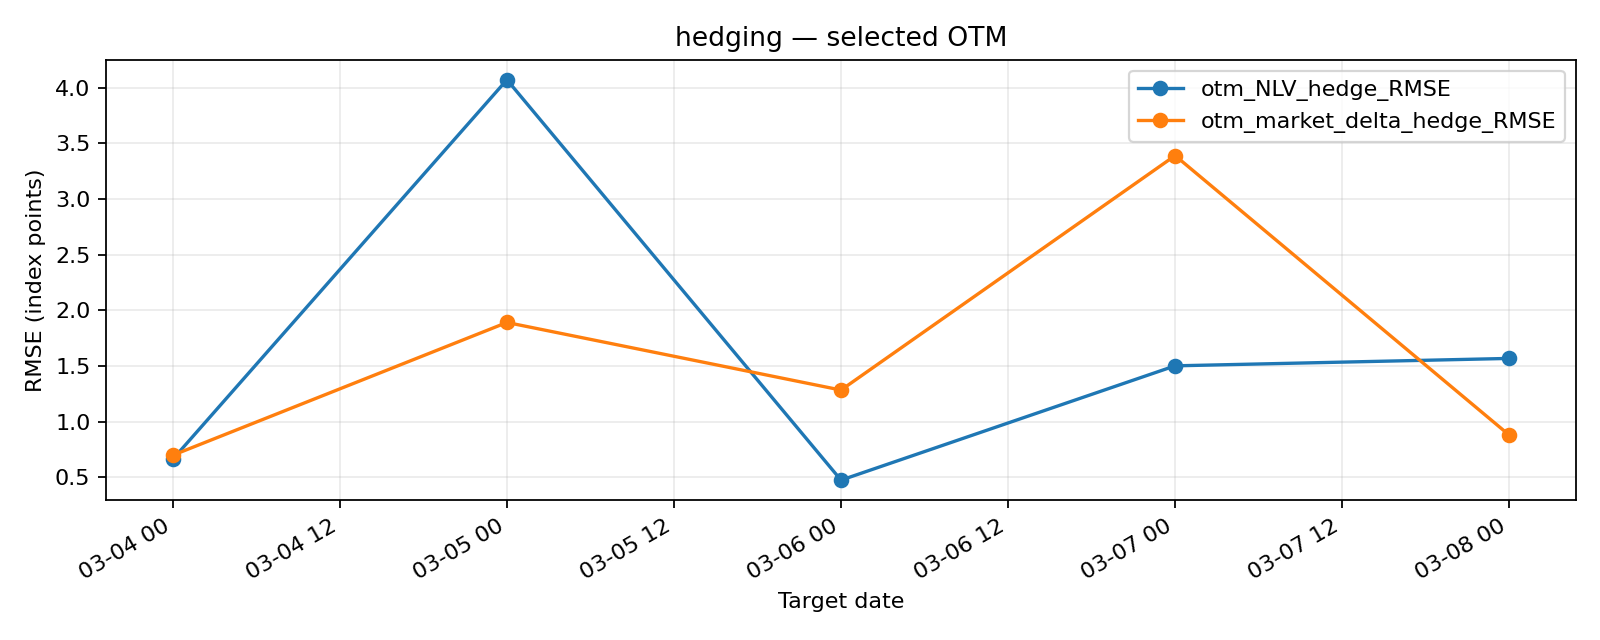

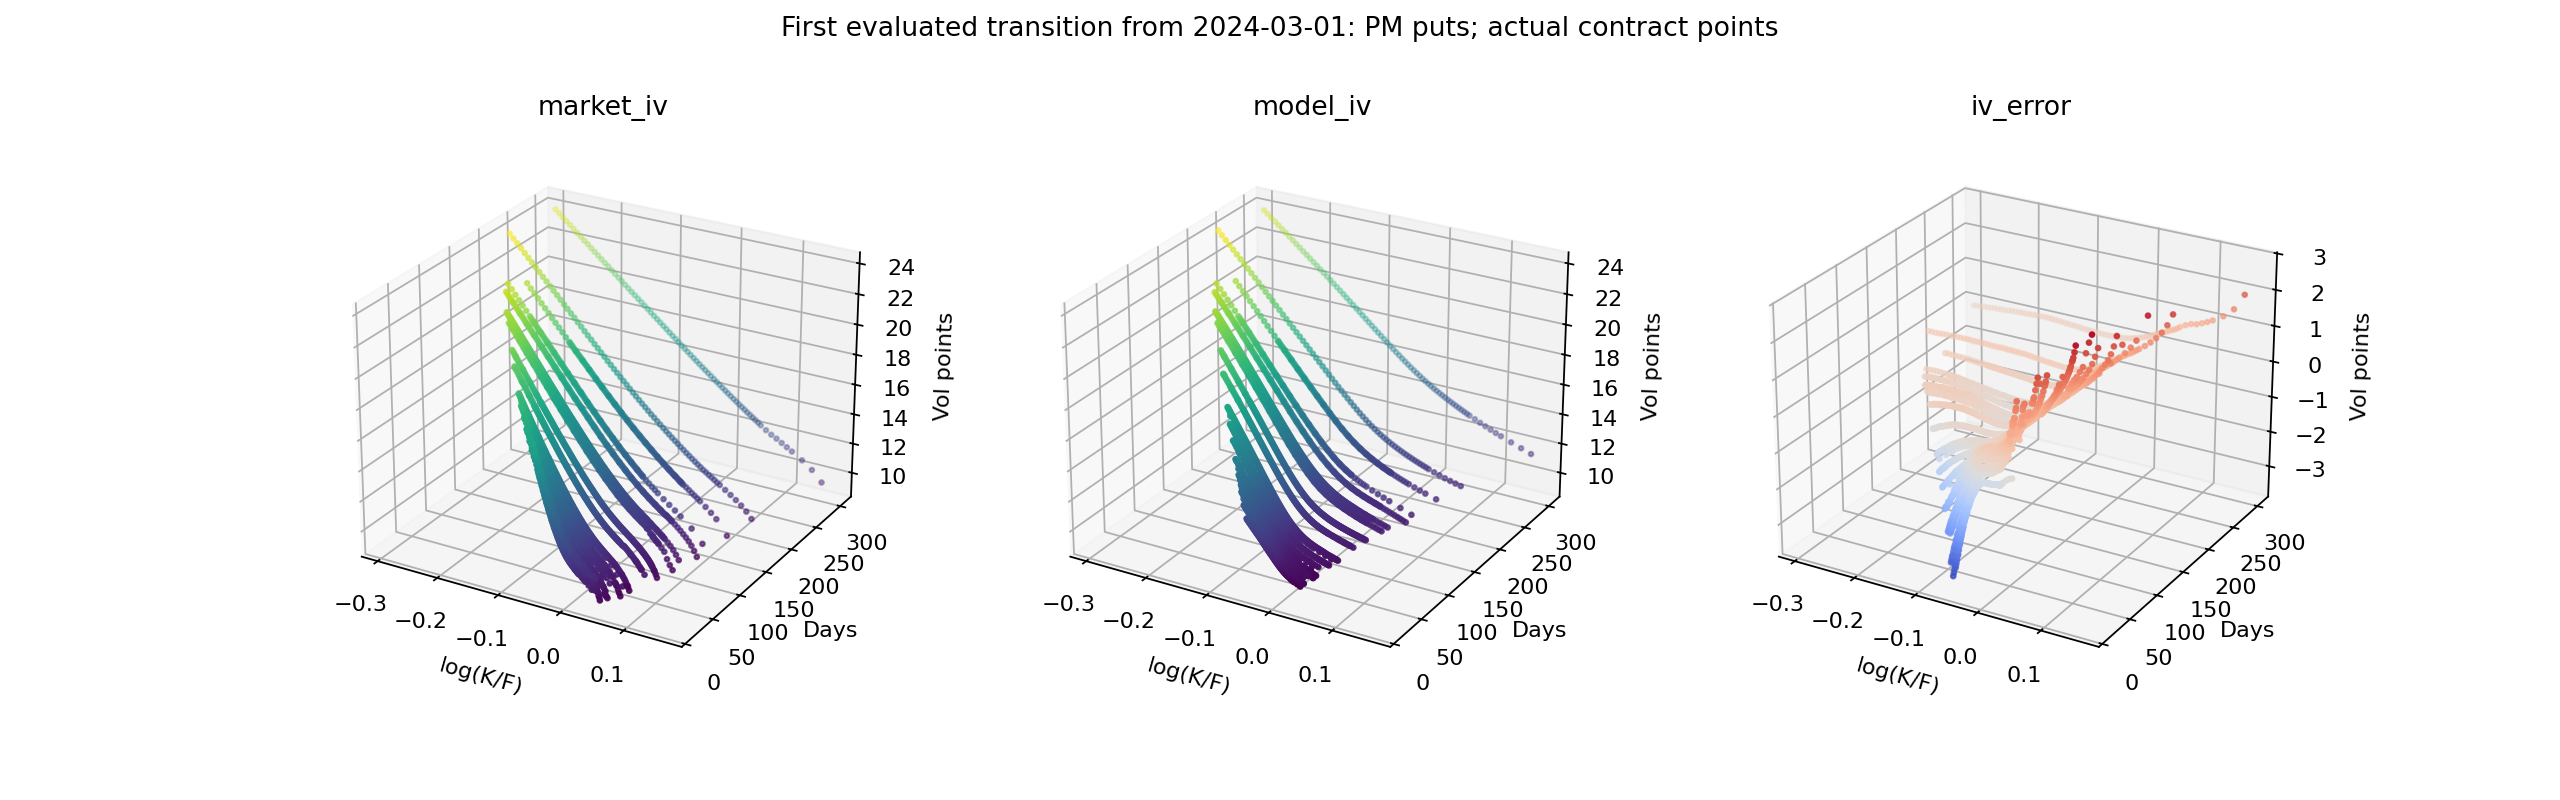

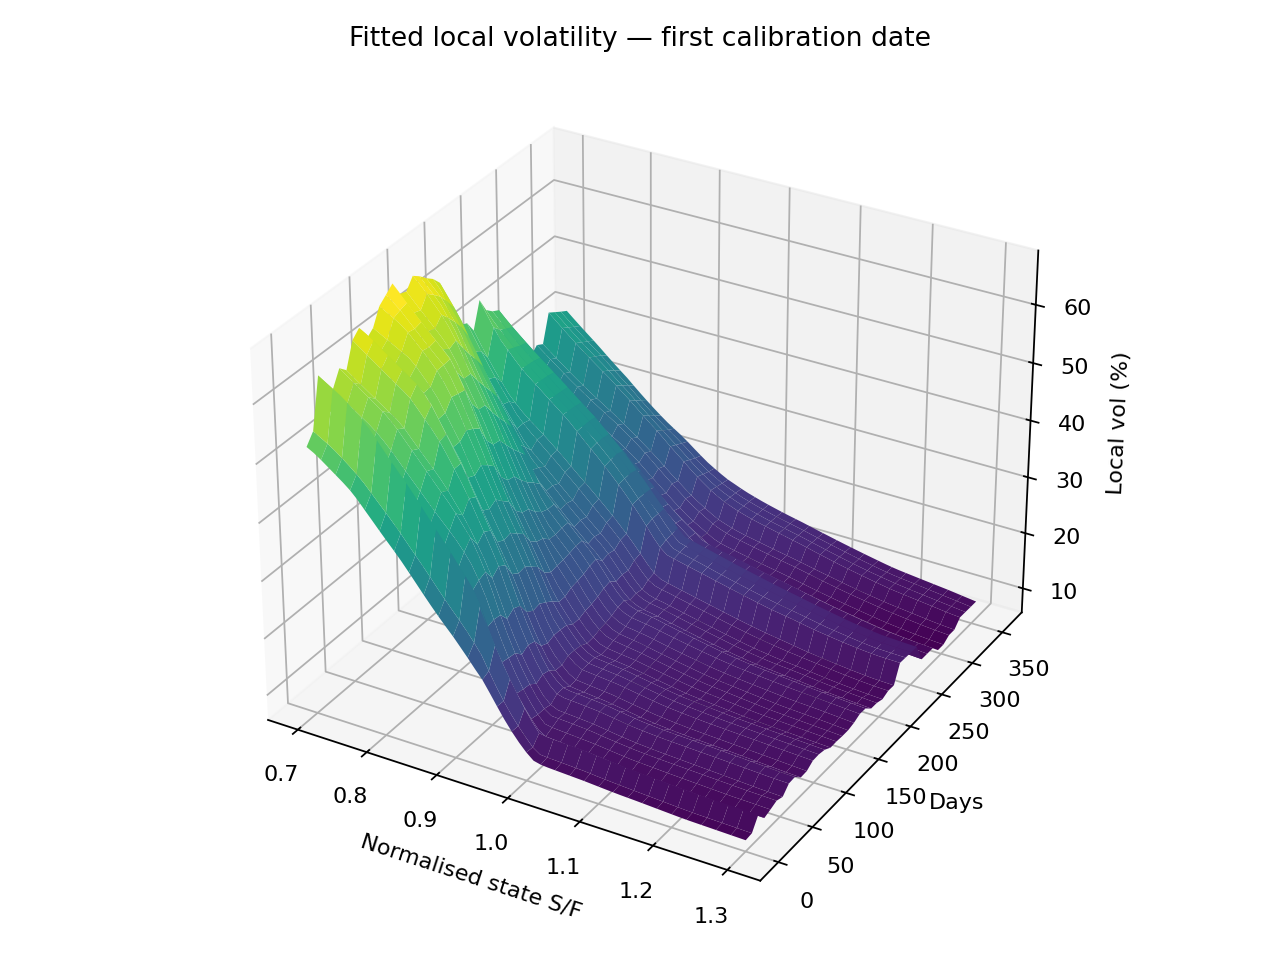

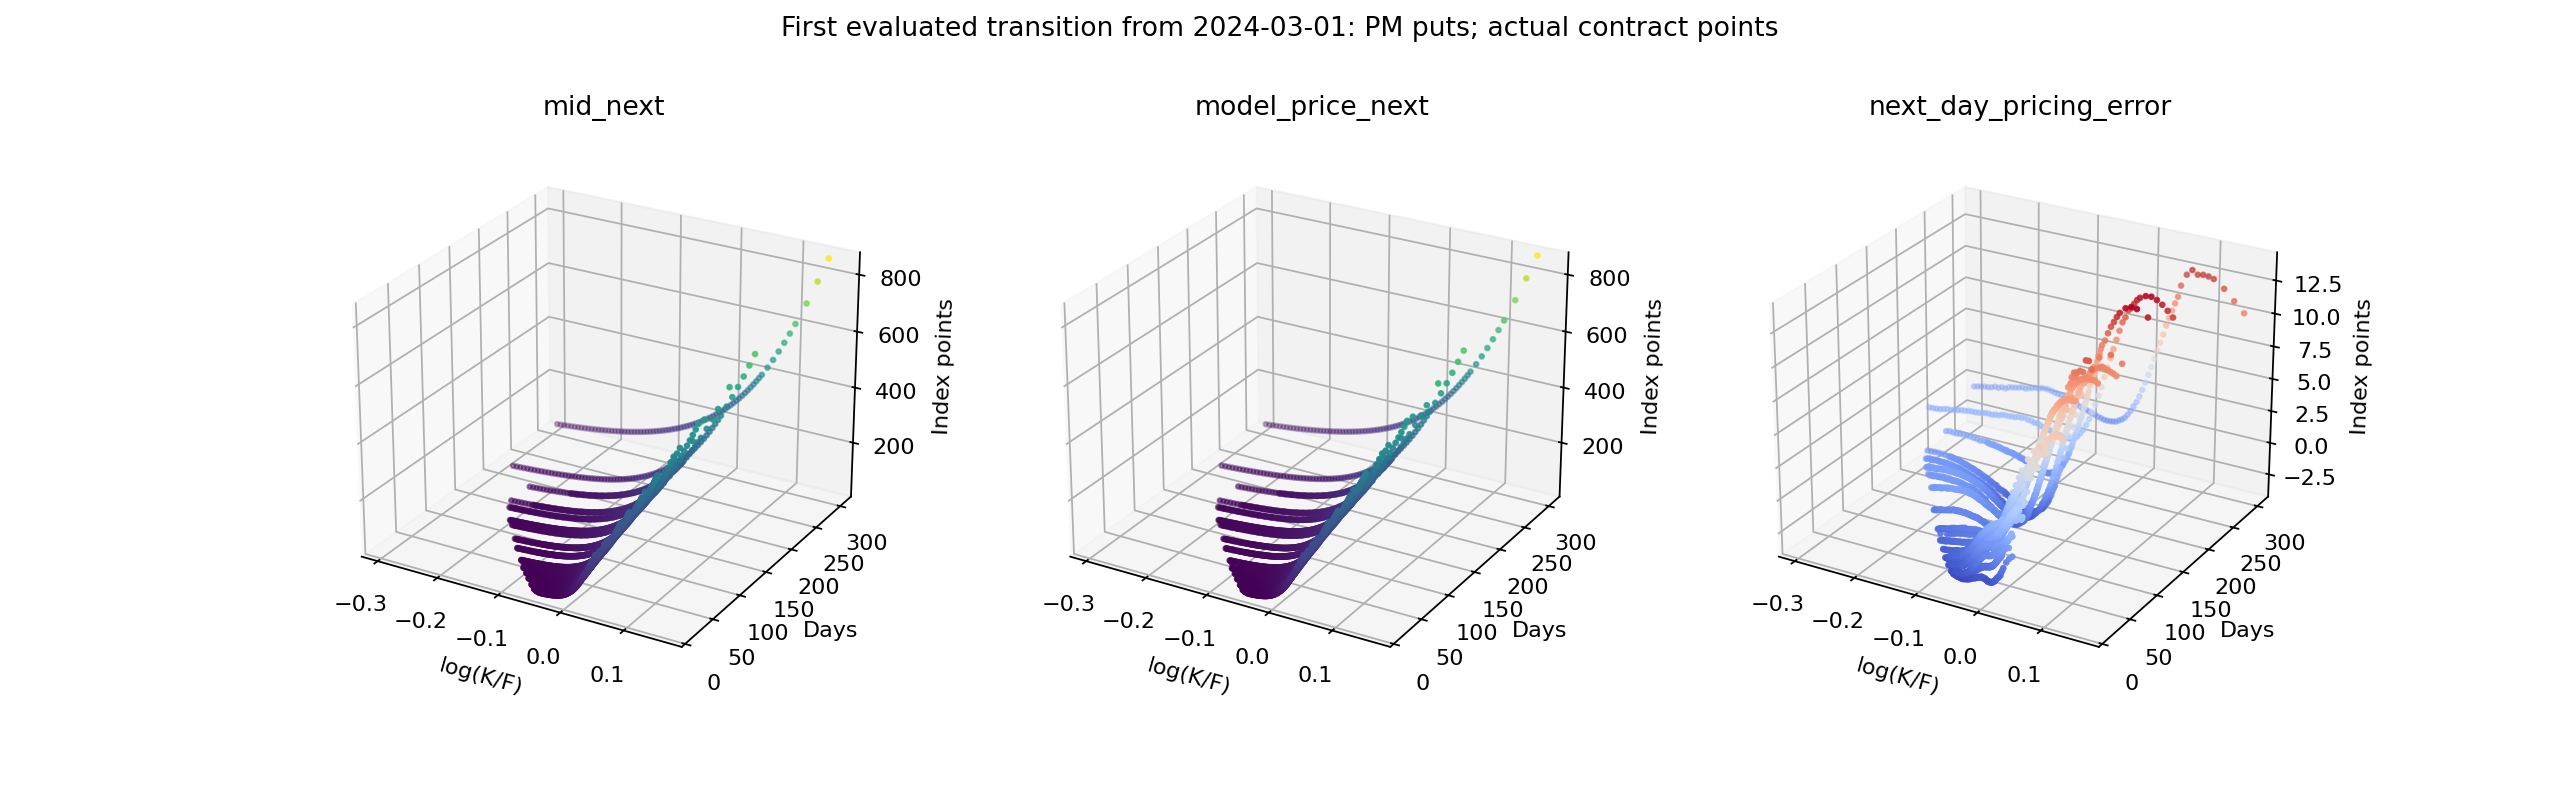

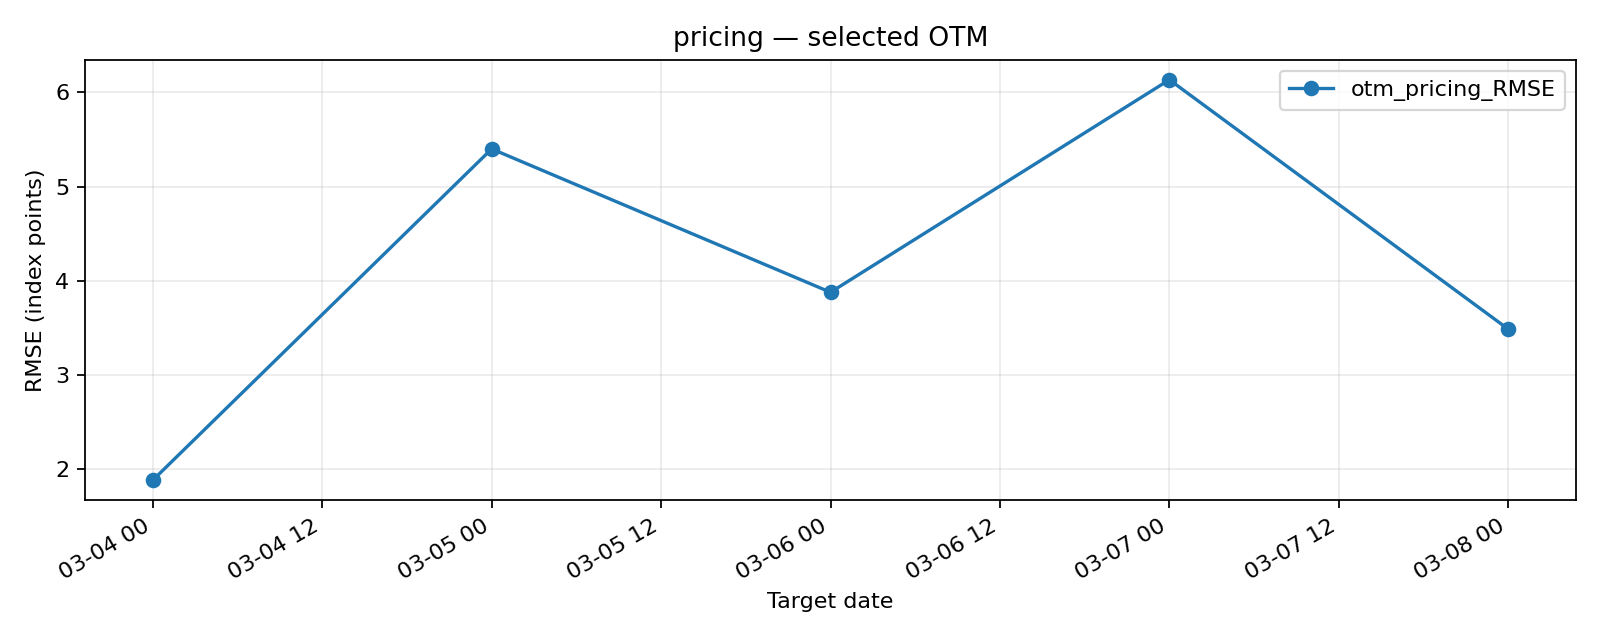

In [90]:
PLOT_SCRIPT=r"""
import sys
from pathlib import Path
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

root=Path(sys.argv[1]); report=root/'reports'; plots=root/'plots'; plots.mkdir(exist_ok=True)
daily=pd.read_csv(root/'daily_summary.csv',parse_dates=['next_date'])
for name,columns in [('pricing',['otm_pricing_RMSE']),('hedging',['otm_NLV_hedge_RMSE','otm_market_delta_hedge_RMSE'])]:
    fig,ax=plt.subplots(figsize=(10,4))
    for col in columns: ax.plot(daily.next_date,daily[col],marker='o',label=col)
    ax.set(title=name+' — selected OTM',xlabel='Target date',ylabel='RMSE (index points)')
    ax.legend(); ax.grid(alpha=.25); fig.autofmt_xdate(); fig.tight_layout()
    fig.savefig(plots/(name+'.png'),dpi=160); plt.close(fig)
d=pd.read_csv(report/'diagnostic_contracts.csv',low_memory=False)
date=d.date.iloc[0]; d=d.loc[(d.date==date)&(d.cp_flag=='P')&(d.am_settlement==0)].copy()
d['days']=365*d.T_next
for label,cols,scale in [('price',['mid_next','model_price_next','next_day_pricing_error'],1),('iv',['market_iv','model_iv','iv_error'],100)]:
    g=d.dropna(subset=cols)
    if g.empty: continue
    fig=plt.figure(figsize=(16,5))
    low=g[cols[:2]].min().min()*scale; high=g[cols[:2]].max().max()*scale
    for i,col in enumerate(cols,1):
        ax=fig.add_subplot(1,3,i,projection='3d')
        z=g[col]*scale; ax.scatter(g.k_next,g.days,z,c=z,cmap='viridis' if i<3 else 'coolwarm',s=4)
        ax.set(xlabel='log(K/F)',ylabel='Days',zlabel='Index points' if label=='price' else 'Vol points',title=col)
        if i<3 and high>low: ax.set_zlim(low,high)
        ax.view_init(25,-60)
    fig.suptitle(f'First evaluated transition from {date}: PM puts; actual contract points')
    fig.subplots_adjust(wspace=.25,bottom=.12,top=.85)
    fig.savefig(plots/(label+'_surface.png'),dpi=160); plt.close(fig)
meshes=sorted(root.glob('eval_*/*_local_vol_mesh.csv'))
if meshes:
    m=pd.read_csv(meshes[0]); pivot=m.pivot(index='t',columns='x',values='sigma')
    import numpy as np
    x,t=np.meshgrid(pivot.columns.to_numpy(),365*pivot.index.to_numpy())
    fig=plt.figure(figsize=(8,6)); ax=fig.add_subplot(111,projection='3d')
    ax.plot_surface(x,t,100*pivot.to_numpy(),cmap='viridis',linewidth=0)
    ax.set(xlabel='Normalised state S/F',ylabel='Days',zlabel='Local vol (%)',title='Fitted local volatility — first calibration date')
    fig.tight_layout(); fig.savefig(plots/'local_vol_surface.png',dpi=160); plt.close(fig)
print('Plots saved to',plots)
"""
from IPython.display import Image, display
for item in RESULTS:
    env=os.environ.copy(); env.pop('KMP_DUPLICATE_LIB_OK',None); env['MPLBACKEND']='Agg'
    child=subprocess.run([sys.executable,'-X','faulthandler','-c',PLOT_SCRIPT,item['folder']],
                         env=env,capture_output=True,text=True)
    (Path(item['folder'])/'plot_process.log').write_text(child.stdout+'\n'+child.stderr,encoding='utf-8')
    if child.returncode:
        print('Plot process failed; numerical files intact:',item['folder'],child.stderr[-1500:])
    else:
        print(child.stdout)
        for path in sorted((Path(item['folder'])/'plots').glob('*.png')): display(Image(filename=str(path)))


## Completion checklist and interpretation

- Smoke outputs are engineering checks only.
- Research modes must report the CPU checkpoint digest and must never cold-start silently.
- Start with `gpu_reference_8k`; compare one ablation at a time under common seeds and shocks.
- The fixed reference uses update 15. Bounded selection compares exactly 0, 5, 10 and 15.
- `longer_patience` counts failed monitoring occasions and is a separate, more expensive experiment.
- Inspect GPU/CPU parity, state-dependent delta, exact-maturity and grid diagnostics before ranking.
- Report sticky-normalised and frozen-physical sensitivities by their explicit names.
- Use multiple confirmation seeds; never select the best seed.
- March 8–28 is observed. Only later data can supply an untouched test.
- Numerical CSVs are saved before isolated plotting, so a plotting failure does not require training.
- This notebook tests the direct neural local-volatility coefficient; it is not a replication of
  Fan's neural-surface/Dupire construction.

### Build-time validation

All code cells were compiled after generation. Every named configuration was constructed and passed
`validate_config`. Static checks confirmed CUDA is mandatory by default, research modes require a
CPU checkpoint, the oversized Sabaté configuration is absent, bounded selection contains exactly
updates 0/5/10/15, and the MSE-aligned Huber objective and replay coefficient are present. Pure
loader tests confirmed clear errors for missing and incompatible CPU checkpoints. No calibration
was started during build validation. CUDA numerical parity, peak VRAM and wall-clock measurements
must be produced on the target GTX 1660 Ti.
